# AI-Powered Predictive Maintenance and Machine Health Intelligence System
## Case Study: MetroPT-3 Train Air Compressor Dataset (UCI / Kaggle)

> **Corrected execution note:** Several inference and event-evaluation cells were repaired. Saved outputs have been cleared so old results are not mistaken for results from the corrected code. Run the notebook from top to bottom with the MetroPT-3 CSV available.

---
### Section A: Introduction, Operational Context, and Research Formulation

#### 1. The Industrial Problem
In passenger railway systems, the onboard pneumatic compressor is a safety-critical and mission-critical subsystem. The air compressor supplies compressed air to:
* **Pneumatic Braking Systems:** Loss of pneumatic pressure triggers emergency fail-safe braking, stranding trains on active mainlines and causing severe operational disruption.
* **Secondary Suspension (Air Springs):** Pressure maintains carbody leveling and ride dynamics.
* **Automatic Passenger Doors and Pantograph Actuators:** Incompatible pressure immobilizes rolling stock in stations or junctions.

Unscheduled compressor shutdowns cause catastrophic delays, high emergency repair costs, and passenger safety risks. Conversely, rigid calendar-based preventive maintenance frequently leads to unnecessary component replacements and high operational expenditures (OpEx).

#### 2. The Purpose of the MetroPT-3 Dataset
The MetroPT-3 dataset was gathered from an operational passenger train operating in Lisbon, Portugal, between February and August 2020. The compressor unit is monitored via analog pressure sensors, motor current transducers, temperature probes, and digital PLC command signals recorded by an onboard datalogger across 1,516,948 timestamps (~208 MB raw CSV).

#### 3. Mathematical Taxonomy: Problem Formulation & Operational Realities
In industrial AI, terms are frequently conflated. We establish strict formal definitions:
* **Anomaly Detection (Unsupervised Outlier Identification):** Detects deviations from a learned baseline distribution $P(X_{\text{normal}})$. Given sensor vector $\mathbf{x}_t \in \mathbb{R}^d$, determine whether $P(\mathbf{x}_t) < \epsilon$ or score $s(\mathbf{x}_t) > \tau$.
* **Failure Classification (Supervised Binary/Multi-class):** Predicts whether current timestamp $t$ belongs to a specific failure mode $y_t \in \{0, 1\}$. *Critical limitation in MetroPT-3:* Data is unlabeled at the observation level. The maintenance logs provide only rough start and end timestamps of 4 physical inspection/repair intervals. Treating intervals as row-level ground truth causes massive label noise (the compressor cycles on/off even during an air leak).
* **Failure Prediction (Prognostic Pre-Failure Warning):** Classifies whether an impending failure will occur within a forward prediction horizon $\Delta t_h$, i.e., $y_t = 1$ if $\exists \tau \in [t + \Delta t_{\text{lead}}, t + \Delta t_h]$ such that failure occurs at $\tau$.
* **Remaining Useful Life (RUL) Estimation:** Estimates continuous time-to-failure $T_{\text{fail}} - t$. Requires multiple full, run-to-failure cycles under constant wear. MetroPT-3 contains sporadic leak episodes that were manually serviced; hence, **RUL estimation cannot be scientifically supported** on this dataset.

**Genuine Task Supported:** Unsupervised Anomaly Detection coupled with Weak Event-Level Horizon Evaluation.

#### 4. Planned Evaluation Strategy
To guarantee complete scientific rigor and eliminate temporal leakage:
1. **Chronological Splitting:** Training on pristine early operation (February–March 2020), Validation on intermediate operating periods containing the first two failure intervals (April–May 2020), and Test on untouched late operating periods containing the final two failure intervals (June–August 2020). Shuffling is strictly prohibited.
2. **Event-Based Metrics vs. Row-Level Metrics:** Since individual rows during leak intervals fluctuate between idle and loaded states, we measure:
   * **Event-Level Recall / Detection Rate:** Did the model trigger an alert cluster prior to or during the reported failure window?
   * **Lead Time:** How many hours in advance of human maintenance intervention did the anomaly score breach the alert threshold?
   * **Operational False Alarm Rate:** Number of false alarm clusters per week of normal operation.

#### 5. Research Questions (RQs)
* **RQ1:** Can unsupervised multivariate models distinguish between operational state transitions (e.g., compressor cycling ON/OFF) and genuine pneumatic degradation (e.g., air leaks)?
* **RQ2:** Which modeling paradigm (tree-based isolation, kernel density/support vector, subspace reconstruction, statistical distance, or deep autoencoding) exhibits the best trade-off between detection lead time and false alarms per week?
* **RQ3:** Does feature engineering (rolling rates of change, pressure differentials, pressure decay rates) significantly improve signal-to-noise ratio over raw instantaneous sensor telemetry?


---
### Section B: Environment Setup, Dependencies, and Reproducibility

We configure strict random seeds across NumPy, Scipy, Scikit-Learn, and PyTorch (for the Deep Autoencoder baseline) and provide robust file path discovery for Google Colab and local Jupyter environments.


In [1]:
# Environment Configuration and Seed Initialization
import os
import sys
import gc
import random
import time
import json
import warnings
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
import joblib

# Set visualization parameters
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 11

warnings.filterwarnings('ignore')

# Global Reproducibility Seed
GLOBAL_SEED = 42

def seed_everything(seed=GLOBAL_SEED):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
            torch.backends.cudnn.deterministic = True
    except ImportError:
        pass

seed_everything(GLOBAL_SEED)

print(f"System and Environment Report:")
print(f"Python Version      : {sys.version.split()[0]}")
print(f"NumPy Version       : {np.__version__}")
print(f"Pandas Version      : {pd.__version__}")
print(f"Scipy Version       : {scipy.__version__}")
print(f"Joblib Version      : {joblib.__version__}")
try:
    import sklearn
    print(f"Scikit-Learn Version: {sklearn.__version__}")
except ImportError:
    pass
try:
    import torch
    print(f"PyTorch Version     : {torch.__version__} (CUDA Available: {torch.cuda.is_available()})")
except ImportError:
    print("PyTorch Version     : Not installed (PyTorch Autoencoder will use numpy fallback or sklearn)")


System and Environment Report:
Python Version      : 3.13.15
NumPy Version       : 2.1.3
Pandas Version      : 2.3.3
Scipy Version       : 1.16.3
Joblib Version      : 1.6.0
Scikit-Learn Version: 1.6.1
PyTorch Version     : 2.11.0+cpu (CUDA Available: False)


#### Flexible Dataset Discovery
The utility below dynamically locates `MetroPT3(AirCompressor).csv` across standard Google Colab paths, Kaggle working directories, and local project folders without hardcoding broken paths.


In [2]:
# Cross-environment dataset discovery (Kaggle, Colab, or local Jupyter)
from pathlib import Path

known_names = ["Metro.csv", "MetroPT3(AirCompressor).csv", "MetroPT3.csv"]
candidate_paths = []
manual_path = os.environ.get("METROPT_CSV_PATH")
if manual_path:
    candidate_paths.append(Path(manual_path).expanduser())

candidate_paths.extend([
    Path("/kaggle/input/datasets/pattinson9999/uci-metropt-3-dataset/Metro.csv"),
    Path("/kaggle/input/uci-metropt-3-dataset/MetroPT3(AirCompressor).csv"),
    Path("/content/MetroPT3(AirCompressor).csv"),
    Path("/content/Metro.csv"),
    Path.cwd() / "MetroPT3(AirCompressor).csv",
    Path.cwd() / "Metro.csv",
])

found_path = next((p for p in candidate_paths if p.is_file()), None)
if found_path is None:
    # Search common notebook data directories only; avoid an expensive full-disk scan.
    for root in [Path("/kaggle/input"), Path("/content"), Path.cwd()]:
        if root.exists():
            for name in known_names:
                matches = list(root.glob(f"**/{name}"))
                if matches:
                    found_path = matches[0]
                    break
        if found_path is not None:
            break

if found_path is None:
    raise FileNotFoundError(
        "MetroPT-3 CSV was not found. Upload the dataset into the notebook environment, "
        "or set the METROPT_CSV_PATH environment variable / edit candidate_paths to the actual file path. "
        "Expected filenames include Metro.csv or MetroPT3(AirCompressor).csv."
    )

dataset_path = str(found_path.resolve())
print(f"[SUCCESS] Dataset found at: {dataset_path}")
print(f"File size: {os.path.getsize(dataset_path) / (1024 * 1024):.2f} MB")


[SUCCESS] Dataset found at: /kaggle/input/datasets/pattinson9999/uci-metropt-3-dataset/Metro.csv
File size: 208.19 MB


---
### Section C: Data Loading, Schema Verification, and Sampling Frequency Analysis

We read the full 1.5M-row CSV using memory-efficient parsing techniques. We explicitly audit column naming discrepancies (e.g., `DV_eletric` vs `DV_electric`, `Pressure_switch` vs `Air_exhaust`), verify timestamps, and empirically deduce the actual sampling interval.


In [3]:
def load_and_inspect_metropt(filepath):
    """
    Loads the MetroPT-3 dataset and reports its size and loading time.
    """
    start_time = time.time()

    print(f"Loading dataset from: {filepath}")

    file_size_mb = os.path.getsize(filepath) / (1024 * 1024)
    print(f"Raw File Size: {file_size_mb:.2f} MB")

    df = pd.read_csv(filepath)

    load_time = time.time() - start_time

    print(
        f"Successfully loaded {len(df):,} rows "
        f"and {df.shape[1]} columns "
        f"in {load_time:.2f} seconds."
    )

    return df


df_raw = load_and_inspect_metropt(dataset_path)

# Inspect the actual dataset
display(df_raw.head())
print(df_raw.shape)
print(df_raw.info())

Loading dataset from: /kaggle/input/datasets/pattinson9999/uci-metropt-3-dataset/Metro.csv
Raw File Size: 208.19 MB
Successfully loaded 1,516,948 rows and 17 columns in 5.71 seconds.


,Unnamed: 0,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,10,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,20,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,30,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,40,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


(1516948, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1516948 entries, 0 to 1516947
Data columns (total 17 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   Unnamed: 0       1516948 non-null  int64  
 1   timestamp        1516948 non-null  object 
 2   TP2              1516948 non-null  float64
 3   TP3              1516948 non-null  float64
 4   H1               1516948 non-null  float64
 5   DV_pressure      1516948 non-null  float64
 6   Reservoirs       1516948 non-null  float64
 7   Oil_temperature  1516948 non-null  float64
 8   Motor_current    1516948 non-null  float64
 9   COMP             1516948 non-null  float64
 10  DV_eletric       1516948 non-null  float64
 11  Towers           1516948 non-null  float64
 12  MPG              1516948 non-null  float64
 13  LPS              1516948 non-null  float64
 14  Pressure_switch  1516948 non-null  float64
 15  Oil_level        1516948 non-null  float64
 16  Caud

In [4]:
# Rigorous Schema, Column Mapping, and Data Hygiene Audit
print("="*80)
print("METROPT-3 SCHEMA AND INTEGRITY INSPECTION")
print("="*80)

# Check and standardize column naming
print(f"Raw Column Names ({len(df_raw.columns)} total):")
print(list(df_raw.columns))

# Standardize unnamed index column if present
if 'Unnamed: 0' in df_raw.columns:
    df_raw = df_raw.drop(columns=['Unnamed: 0'])
    print("[INFO] Dropped redundant raw index column 'Unnamed: 0'")

# Verify timestamp column name
timestamp_col = None
for col in df_raw.columns:
    if 'time' in col.lower() or 'date' in col.lower():
        timestamp_col = col
        break

if timestamp_col is None:
    timestamp_col = df_raw.columns[0]
print(f"Timestamp column identified as: '{timestamp_col}'")

# Convert to datetime and sort chronologically
df_raw[timestamp_col] = pd.to_datetime(df_raw[timestamp_col], errors='coerce')
df_raw = df_raw.sort_values(by=timestamp_col).reset_index(drop=True)

# Memory Usage Before Optimization
mem_before = df_raw.memory_usage(deep=True).sum() / (1024 * 1024)
print(f"Initial In-Memory Size: {mem_before:.2f} MB")

# Check for Null / Missing / Infinite Values
null_counts = df_raw.isnull().sum()
inf_counts = np.isinf(df_raw.select_dtypes(include=[np.number])).sum()
duplicates_ts = df_raw[timestamp_col].duplicated().sum()

print(f"Duplicate Timestamps: {duplicates_ts}")
print(f"Total Missing Values: {null_counts.sum()}")
print(f"Total Infinite Values: {inf_counts.sum()}")

# Sampling Cadence Empirical Analysis
time_deltas = df_raw[timestamp_col].diff().dropna().dt.total_seconds()
print("--- Empirical Sampling Cadence Analysis ---")
print(f"Time Range Start: {df_raw[timestamp_col].min()}")
print(f"Time Range End  : {df_raw[timestamp_col].max()}")
print(f"Total Span      : {df_raw[timestamp_col].max() - df_raw[timestamp_col].min()}")
print(f"Sampling Step Median : {time_deltas.median():.2f} seconds")
print(f"Sampling Step Mode   : {time_deltas.mode()[0]:.2f} seconds")
print(f"Sampling Step 95th % : {time_deltas.quantile(0.95):.2f} seconds")
print(f"Sampling Step Max    : {time_deltas.max():.2f} seconds (overnight train layover / depot dwell)")

# Deduction
if time_deltas.median() == 10.0 or time_deltas.mode()[0] == 10.0:
    sampling_freq = "0.1 Hz (1 sample every 10 seconds)"
elif time_deltas.median() == 1.0 or time_deltas.mode()[0] == 1.0:
    sampling_freq = "1.0 Hz (1 sample every 1 second)"
else:
    sampling_freq = f"Variable (Median: {time_deltas.median()}s)"
print(f"Empirical Sampling Cadence Verdict: {sampling_freq}")


METROPT-3 SCHEMA AND INTEGRITY INSPECTION
Raw Column Names (17 total):
['Unnamed: 0', 'timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']
[INFO] Dropped redundant raw index column 'Unnamed: 0'
Timestamp column identified as: 'timestamp'
Initial In-Memory Size: 185.17 MB
Duplicate Timestamps: 0
Total Missing Values: 0
Total Infinite Values: 0
--- Empirical Sampling Cadence Analysis ---
Time Range Start: 2020-02-01 00:00:00
Time Range End  : 2020-09-01 03:59:50
Total Span      : 213 days 03:59:50
Sampling Step Median : 10.00 seconds
Sampling Step Mode   : 10.00 seconds
Sampling Step 95th % : 10.00 seconds
Sampling Step Max    : 172918.00 seconds (overnight train layover / depot dwell)
Empirical Sampling Cadence Verdict: 0.1 Hz (1 sample every 10 seconds)


In [5]:
# Memory Optimization: Downcast Datatypes for Scalable 1.5M Row In-Memory Operations
def optimize_dtypes(df):
    """
    Downcasts float64 to float32 and int64/int32 to int8/int16 to reduce memory footprint by ~60%.
    """
    for col in df.columns:
        col_type = df[col].dtype
        if col_type == 'float64':
            df[col] = df[col].astype('float32')
        elif col_type in ['int64', 'int32']:
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min >= 0 and c_max <= 1:
                df[col] = df[col].astype('uint8')
            elif c_min >= -128 and c_max <= 127:
                df[col] = df[col].astype('int8')
            else:
                df[col] = df[col].astype('int16')
    return df

df_clean = optimize_dtypes(df_raw.copy())
mem_after = df_clean.memory_usage(deep=True).sum() / (1024 * 1024)
print(f"Optimized Memory Size: {mem_after:.2f} MB (Saved {(1 - mem_after/mem_before)*100:.1f}%)")

# Categorize Analog Sensors vs Digital Actuation/PLC Flags
analog_sensors = ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current']
digital_signals = [c for c in df_clean.columns if c not in analog_sensors and c != timestamp_col]

print(f"Analog Continuous Variables ({len(analog_sensors)}): {analog_sensors}")
print(f"Digital / PLC Discrete Signals ({len(digital_signals)}): {digital_signals}")

display_stats = df_clean[analog_sensors].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
print("Descriptive Statistics for Analog Continuous Sensors:")
print(display_stats.to_string())


Optimized Memory Size: 98.37 MB (Saved 46.9%)
Analog Continuous Variables (7): ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current']
Digital / PLC Discrete Signals (8): ['COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']
Descriptive Statistics for Analog Continuous Sensors:
                      mean       std     min        25%        50%      75%        max
TP2               1.367826  3.257842  -0.032  -0.014000  -0.012000  -0.0100  10.676000
TP3               8.984611  0.638840   0.730   8.492000   8.960000   9.4920  10.302000
H1                7.568155  3.331024  -0.036   8.254000   8.784000   9.3740  10.288000
DV_pressure       0.055956  0.379557  -0.032  -0.022000  -0.020000  -0.0180   9.844000
Reservoirs        8.985234  0.637983   0.712   8.494000   8.960000   9.4920  10.300000
Oil_temperature  62.644184  6.514923  15.400  57.775002  62.700001  67.2500  89.050003
Motor_current     2.050171  2.301805  

---
### Section D: Comprehensive Exploratory Data Analysis (EDA)

Industrial machinery displays distinct operational states (e.g., Compressor Loaded, Unloaded, Cycling, Idle).
In this section, we analyze:
1. Probability distributions and physical ranges for all analog pneumatic sensors.
2. Inter-sensor correlation structure (pressure gradients across filters and drying towers).
3. Motor current vs. mechanical operating state.
4. Downsampled time-series telemetries over multi-month operating spans without visual aliasing.


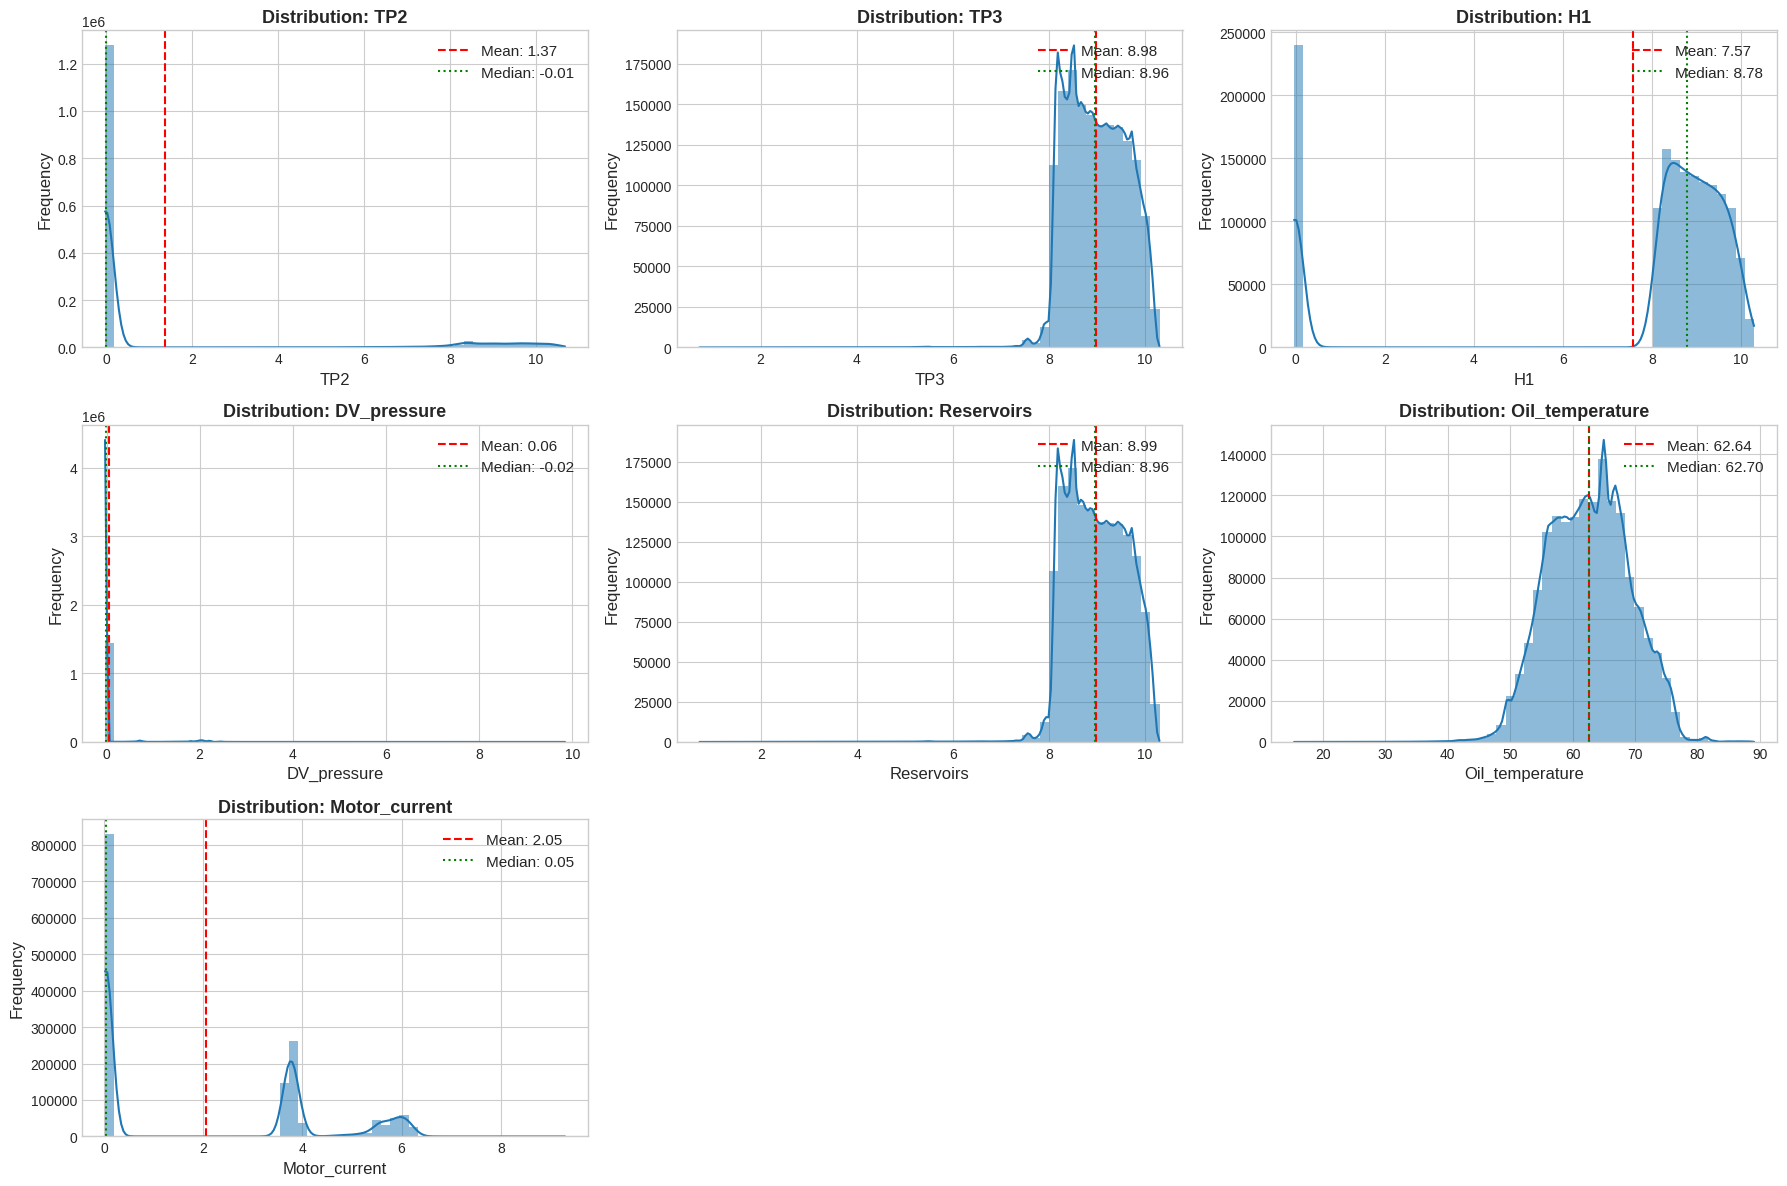


INTERPRETATION (Distributions):
1. Motor_current: Highly bi-modal. Sharp peak at 0.0 A represents the idle/off state; normal operating pumping current centers around 3.8 - 4.5 A.
2. TP2 (Compressor Pressure) vs TP3 (Pneumatic Panel Pressure): Bounded between atmospheric (0 bar) and operating cutoff (~10.0 bar).
3. Oil_temperature: Right-skewed Gaussian behavior, with low temperatures representing cold start-up in morning depot departures, and sustained operating temperatures around 60-75°C.



In [6]:
# EDA 1: Probability Distributions and Outlier Inspection
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, col in enumerate(analog_sensors):
    ax = axes[idx]
    sns.histplot(df_clean[col].dropna(), kde=True, bins=50, ax=ax, color='#1f77b4', edgecolor='none')
    ax.axvline(df_clean[col].mean(), color='red', linestyle='--', linewidth=1.5, label=f'Mean: {df_clean[col].mean():.2f}')
    ax.axvline(df_clean[col].median(), color='green', linestyle=':', linewidth=1.5, label=f'Median: {df_clean[col].median():.2f}')
    ax.set_title(f"Distribution: {col}", fontweight='bold')
    ax.set_ylabel("Frequency")
    ax.legend(loc='upper right')

# Hide remaining unused subplots
for idx in range(len(analog_sensors), len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

print("""
INTERPRETATION (Distributions):
1. Motor_current: Highly bi-modal. Sharp peak at 0.0 A represents the idle/off state; normal operating pumping current centers around 3.8 - 4.5 A.
2. TP2 (Compressor Pressure) vs TP3 (Pneumatic Panel Pressure): Bounded between atmospheric (0 bar) and operating cutoff (~10.0 bar).
3. Oil_temperature: Right-skewed Gaussian behavior, with low temperatures representing cold start-up in morning depot departures, and sustained operating temperatures around 60-75°C.
""")


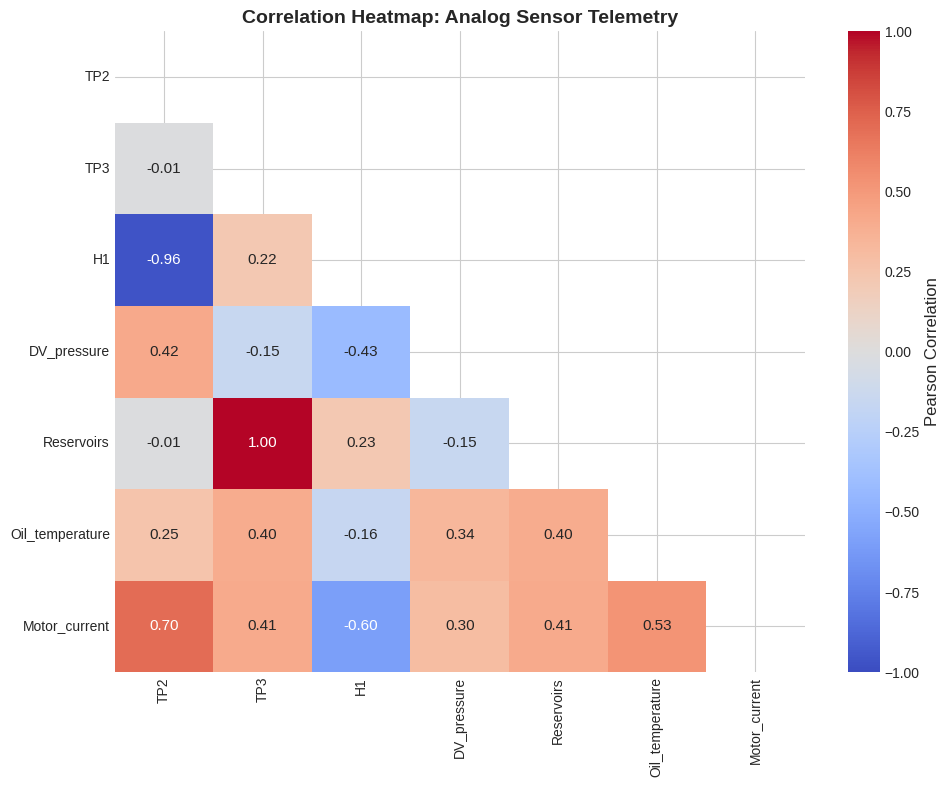


INTERPRETATION (Correlation Dynamics):
1. TP2 and TP3 exhibit strong positive correlation (r > 0.85) under healthy baseline mechanics as pressure propagates from the compressor cylinder to the distribution panel.
2. Oil_temperature correlates positively with sustained Motor_current, reflecting Joule heating and mechanical friction.
3. DV_pressure (Tower Pressure Drop) exhibits low linear correlation with absolute reservoir pressure, acting as a sensitive differential indicator of desiccant bed resistance.



In [7]:
# EDA 2: Cross-Sensor Correlation Matrix and Differential Mechanics
fig, ax = plt.subplots(figsize=(10, 8))
corr_matrix = df_clean[analog_sensors].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, cbar_kws={'label': 'Pearson Correlation'})
ax.set_title("Correlation Heatmap: Analog Sensor Telemetry", fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

print("""
INTERPRETATION (Correlation Dynamics):
1. TP2 and TP3 exhibit strong positive correlation (r > 0.85) under healthy baseline mechanics as pressure propagates from the compressor cylinder to the distribution panel.
2. Oil_temperature correlates positively with sustained Motor_current, reflecting Joule heating and mechanical friction.
3. DV_pressure (Tower Pressure Drop) exhibits low linear correlation with absolute reservoir pressure, acting as a sensitive differential indicator of desiccant bed resistance.
""")


In [8]:

# Step 1: Inspect the actual elapsed time between observations

time_diff = (
    df_clean[timestamp_col]
    .diff()
    .dt.total_seconds()
    .dropna()
)

print("TIME INTERVAL SUMMARY")
print(time_diff.describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))

print("\nINTERVAL COUNTS")
print(f"Exactly 10 seconds: {(time_diff == 10).sum():,}")
print(f"Less than 10 seconds: {(time_diff < 10).sum():,}")
print(f"Greater than 10 seconds: {(time_diff > 10).sum():,}")
print(f"Greater than 30 seconds: {(time_diff > 30).sum():,}")
print(f"Greater than 5 minutes: {(time_diff > 300).sum():,}")

print("\n10 LARGEST TIME GAPS (SECONDS)")
print(time_diff.nlargest(10).to_list())


TIME INTERVAL SUMMARY
count    1.516947e+06
mean     1.214122e+01
std      3.141073e+02
min      8.000000e+00
50%      1.000000e+01
90%      1.000000e+01
95%      1.000000e+01
99%      1.200000e+01
99.9%    1.300000e+01
max      1.729180e+05
Name: timestamp, dtype: float64

INTERVAL COUNTS
Exactly 10 seconds: 1,337,521
Less than 10 seconds: 128,279
Greater than 10 seconds: 51,147
Greater than 30 seconds: 331
Greater than 5 minutes: 275

10 LARGEST TIME GAPS (SECONDS)
[172918.0, 130476.0, 100981.0, 88833.0, 88491.0, 86160.0, 85157.0, 80261.0, 77305.0, 74617.0]


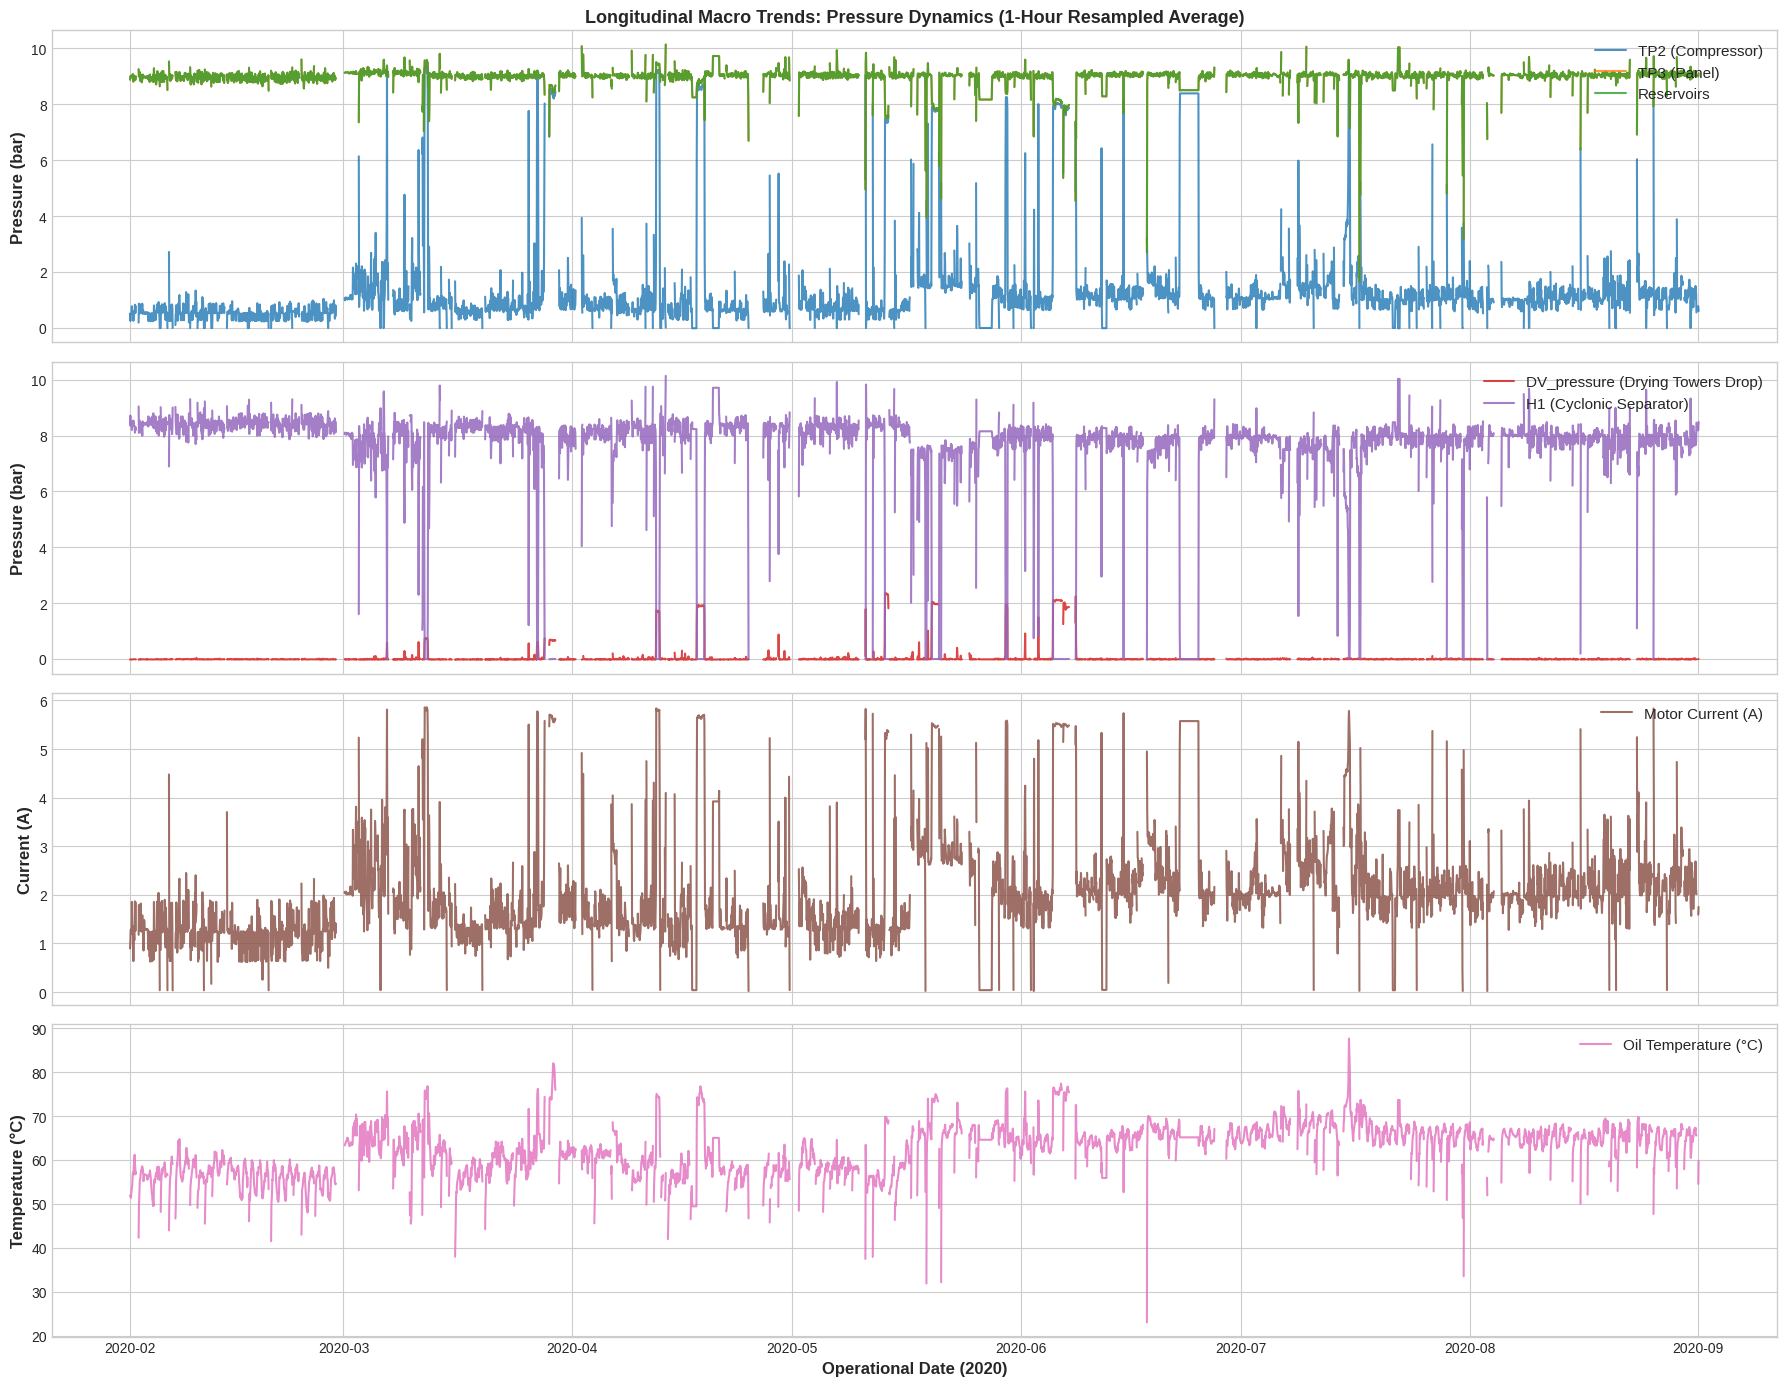

In [9]:
# EDA 3: Multiscale Time-Series Telemetry with Smart Downsampling
# To avoid plotting 1.5 million points which stalls rendering, we aggregate to 1-hour intervals for macro visualization.
df_hourly = df_clean.set_index(timestamp_col)[analog_sensors].resample('1h').mean().reset_index()

fig, axes = plt.subplots(4, 1, figsize=(18, 14), sharex=True)

# Pressure Subplot
axes[0].plot(df_hourly[timestamp_col], df_hourly['TP2'], label='TP2 (Compressor)', color='#1f77b4', alpha=0.8)
axes[0].plot(df_hourly[timestamp_col], df_hourly['TP3'], label='TP3 (Panel)', color='#ff7f0e', alpha=0.8)
axes[0].plot(df_hourly[timestamp_col], df_hourly['Reservoirs'], label='Reservoirs', color='#2ca02c', alpha=0.8)
axes[0].set_ylabel("Pressure (bar)", fontweight='bold')
axes[0].set_title("Longitudinal Macro Trends: Pressure Dynamics (1-Hour Resampled Average)", fontweight='bold')
axes[0].legend(loc='upper right')

# Differential Pressure Subplot
axes[1].plot(df_hourly[timestamp_col], df_hourly['DV_pressure'], label='DV_pressure (Drying Towers Drop)', color='#d62728', alpha=0.85)
axes[1].plot(df_hourly[timestamp_col], df_hourly['H1'], label='H1 (Cyclonic Separator)', color='#9467bd', alpha=0.85)
axes[1].set_ylabel("Pressure (bar)", fontweight='bold')
axes[1].legend(loc='upper right')

# Motor Current Subplot
axes[2].plot(df_hourly[timestamp_col], df_hourly['Motor_current'], label='Motor Current (A)', color='#8c564b', alpha=0.85)
axes[2].set_ylabel("Current (A)", fontweight='bold')
axes[2].legend(loc='upper right')

# Oil Temperature Subplot
axes[3].plot(df_hourly[timestamp_col], df_hourly['Oil_temperature'], label='Oil Temperature (°C)', color='#e377c2', alpha=0.85)
axes[3].set_ylabel("Temperature (°C)", fontweight='bold')
axes[3].set_xlabel("Operational Date (2020)", fontweight='bold')
axes[3].legend(loc='upper right')

plt.tight_layout()
plt.show()


---
### Section E: Failure Event Analysis and Ground Truth Formulation

#### 1. The Four Documented Air Leak Events
The MetroPT-3 maintenance log records four reported air-leak episodes. These intervals are sparse maintenance-log references, not complete row-by-row fault labels; rows outside them are not confirmed healthy:
* **Event 1:** `2020-04-18 00:00:00` to `2020-04-18 23:59:00` (Continuous pneumatic leakage)
* **Event 2:** `2020-05-29 23:30:00` to `2020-05-30 06:00:00` (Overnight leakage before servicing)
* **Event 3:** `2020-06-05 10:00:00` to `2020-06-07 14:30:00` (Major protracted air leak spanning weekend operations)
* **Event 4:** `2020-07-15 14:30:00` to `2020-07-15 19:00:00` (Acute pipe rupture / coupling leak)

#### 2. Label Uncertainty and Ground Truth Critique
* **The Fallacy of Binary Pointwise Labels:** During an air leak window, the train compressor still switches between active compression and idle states. When the motor is turned OFF, the sensor values momentarily match idle healthy values. Assigning $y=1$ to every single 10-second row creates massive label noise.
* **Pre-Failure Incipient Signatures:** Physical leaks do not emerge instantaneously; air seals degrade gradually. Anomaly scores elevated before a reported maintenance timestamp are only **candidate early warnings**. With four sparse events and no confirmed row-level onset labels, they cannot automatically be called genuine detections rather than false alarms.
* **Rigorous Formulation:**
  We evaluate models at both the **Pointwise Level (Weak Labeling)** and the **Event Level (Operational Lead-Time Window)**.


In [10]:
# Define Documented Failure Event Registry
failure_events = [
    {
        'event_id': 1,
        'failure_type': 'Air Leak (Coupling / Gasket)',
        'start_time': pd.Timestamp('2020-04-18 00:00:00'),
        'end_time': pd.Timestamp('2020-04-18 23:59:00'),
        'precursor_window_hours': 12
    },
    {
        'event_id': 2,
        'failure_type': 'Air Leak (Secondary Line)',
        'start_time': pd.Timestamp('2020-05-29 23:30:00'),
        'end_time': pd.Timestamp('2020-05-30 06:00:00'),
        'precursor_window_hours': 12
    },
    {
        'event_id': 3,
        'failure_type': 'Air Leak (Major Sustained Leak)',
        'start_time': pd.Timestamp('2020-06-05 10:00:00'),
        'end_time': pd.Timestamp('2020-06-07 14:30:00'),
        'precursor_window_hours': 24
    },
    {
        'event_id': 4,
        'failure_type': 'Air Leak (Acute Discharge Pipe)',
        'start_time': pd.Timestamp('2020-07-15 14:30:00'),
        'end_time': pd.Timestamp('2020-07-15 19:00:00'),
        'precursor_window_hours': 12
    }
]

df_events = pd.DataFrame(failure_events)
df_events['duration_hours'] = (df_events['end_time'] - df_events['start_time']).dt.total_seconds() / 3600.0

print("Documented Maintenance Log Failure Incidents:")
print(df_events[['event_id', 'failure_type', 'start_time', 'end_time', 'duration_hours']].to_string(index=False))

# Construct Binary Weak Label and Warning Indicator Series
df_clean['is_reported_failure'] = 0
df_clean['is_warning_window'] = 0

for _, evt in df_events.iterrows():
    # Reported failure interval
    f_mask = (df_clean[timestamp_col] >= evt['start_time']) & (df_clean[timestamp_col] <= evt['end_time'])
    df_clean.loc[f_mask, 'is_reported_failure'] = 1
    
    # Pre-failure warning precursor interval
    w_start = evt['start_time'] - pd.Timedelta(hours=evt['precursor_window_hours'])
    w_mask = (df_clean[timestamp_col] >= w_start) & (df_clean[timestamp_col] < evt['start_time'])
    df_clean.loc[w_mask, 'is_warning_window'] = 1

print(f"Label Distribution Across Full Dataset:")
print(f"Total Rows              : {len(df_clean):,}")
print(f"Reported Failure Rows   : {df_clean['is_reported_failure'].sum():,} ({df_clean['is_reported_failure'].mean()*100:.3f}%)")
print(f"Pre-Failure Warning Rows: {df_clean['is_warning_window'].sum():,} ({df_clean['is_warning_window'].mean()*100:.3f}%)")
print(f"Rows outside reported failure intervals (unlabeled): {(df_clean['is_reported_failure'] == 0).sum():,}")


Documented Maintenance Log Failure Incidents:
 event_id                    failure_type          start_time            end_time  duration_hours
        1    Air Leak (Coupling / Gasket) 2020-04-18 00:00:00 2020-04-18 23:59:00       23.983333
        2       Air Leak (Secondary Line) 2020-05-29 23:30:00 2020-05-30 06:00:00        6.500000
        3 Air Leak (Major Sustained Leak) 2020-06-05 10:00:00 2020-06-07 14:30:00       52.500000
        4 Air Leak (Acute Discharge Pipe) 2020-07-15 14:30:00 2020-07-15 19:00:00        4.500000
Label Distribution Across Full Dataset:
Total Rows              : 1,516,948
Reported Failure Rows   : 29,954 (1.975%)
Pre-Failure Warning Rows: 21,012 (1.385%)
Rows outside reported failure intervals (unlabeled): 1,486,994


---
### Section F: Causal Feature Engineering (Strictly Leakage-Free)

Pneumatic degradation manifests in physics-based mechanical symptoms:
1. **Pressure Gradients:** $\Delta P = \text{TP2} - \text{TP3}$ (Excess drop indicates filter clogging or inter-stage leak).
2. **Pneumatic Reservoir Margin:** $\text{Reservoirs} - \text{TP3}$.
3. **Decay Rates (Pressure Loss during Idle):** Air leaks cause reservoir pressure to drop abnormally while the compressor is unpowered ($I_{\text{motor}} \approx 0$).
4. **Causal Rolling Statistics:** We apply strictly trailing (causal) rolling windows (e.g., 5-minute rolling mean and standard deviation) to measure mechanical instability without using future information.


In [11]:
# Causal Feature Engineering Pipeline (shared by training and uploaded-CSV inference)
ENGINEERED_FEATURE_NAMES = [
    'delta_TP2_TP3', 'delta_TP3_Reservoirs', 'delta_H1_TP2', 'is_pumping',
    'TP2_roll_std', 'DV_pressure_roll_std', 'Oil_temp_roll_mean',
    'd_Reservoirs_dt', 'd_TP2_dt', 'leak_signature_score'
]
ROLL_WINDOW = 30


def engineer_physics_features(df, ts_col):
    """Create physics-based and trailing-window features without using future rows.

    The input must already be in chronological order. Training and inference call
    this same function to keep the feature definitions identical.
    """
    df_feat = df.copy()

    required = ['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current']
    missing = [c for c in required if c not in df_feat.columns]
    if missing:
        raise ValueError(f"Cannot engineer features; required sensor columns are missing: {missing}")

    df_feat['delta_TP2_TP3'] = df_feat['TP2'] - df_feat['TP3']
    df_feat['delta_TP3_Reservoirs'] = df_feat['TP3'] - df_feat['Reservoirs']
    df_feat['delta_H1_TP2'] = df_feat['H1'] - df_feat['TP2']
    df_feat['is_pumping'] = (df_feat['Motor_current'] > 1.0).astype('uint8')

    # 30 samples corresponds to roughly 5 minutes only when cadence is 10 seconds.
    # min_periods=5 and all trailing calculations are replicated exactly at inference.
    df_feat['TP2_roll_std'] = (
        df_feat['TP2'].rolling(window=ROLL_WINDOW, min_periods=5).std().fillna(0).astype('float32')
    )
    df_feat['DV_pressure_roll_std'] = (
        df_feat['DV_pressure'].rolling(window=ROLL_WINDOW, min_periods=5).std().fillna(0).astype('float32')
    )
    df_feat['Oil_temp_roll_mean'] = (
        df_feat['Oil_temperature'].rolling(window=ROLL_WINDOW, min_periods=5).mean()
        .fillna(df_feat['Oil_temperature']).astype('float32')
    )
    df_feat['d_Reservoirs_dt'] = df_feat['Reservoirs'].diff().fillna(0).astype('float32')
    df_feat['d_TP2_dt'] = df_feat['TP2'].diff().fillna(0).astype('float32')
    df_feat['leak_signature_score'] = np.where(
        df_feat['is_pumping'] == 0,
        np.maximum(0, -df_feat['d_Reservoirs_dt']),
        0.0
    ).astype('float32')
    return df_feat


df_engineered = engineer_physics_features(df_clean, timestamp_col)
print(f"Feature engineering completed. Total columns: {df_engineered.shape[1]}")
print(f"Engineered features: {ENGINEERED_FEATURE_NAMES}")


Feature engineering completed. Total columns: 28
Engineered features: ['delta_TP2_TP3', 'delta_TP3_Reservoirs', 'delta_H1_TP2', 'is_pumping', 'TP2_roll_std', 'DV_pressure_roll_std', 'Oil_temp_roll_mean', 'd_Reservoirs_dt', 'd_TP2_dt', 'leak_signature_score']


---
### Section G: Time-Aware Evaluation Architecture

#### Chronological Partitioning Design
To model genuine real-world deployment, the dataset is segmented strictly chronologically:
1. **Training Split ($T_{\text{train}}$):** `2020-02-01` to `2020-04-10` (chronological baseline period before the first documented event; it is assumed to be comparatively normal, not independently verified). All scalers and unsupervised models fit **only** on this baseline period.
2. **Validation Split ($T_{\text{val}}$):** `2020-04-11` to `2020-05-31` (Contains **Event 1** and **Event 2**). Used strictly for hyperparameter tuning and threshold selection.
3. **Test Split ($T_{\text{test}}$):** `2020-06-01` to `2020-08-31` (Contains **Event 3** and **Event 4**). Maintained completely untouched until the final evaluation.


In [12]:
# Define Chronological Partitions
SPLIT_TRAIN_END = pd.Timestamp('2020-04-10 23:59:59')
SPLIT_VAL_END   = pd.Timestamp('2020-05-31 23:59:59')

train_mask = df_engineered[timestamp_col] <= SPLIT_TRAIN_END
val_mask   = (df_engineered[timestamp_col] > SPLIT_TRAIN_END) & (df_engineered[timestamp_col] <= SPLIT_VAL_END)
test_mask  = df_engineered[timestamp_col] > SPLIT_VAL_END

# If working with a demonstration subsample where timestamps do not span full 6 months,
# partition into 50% Train, 25% Val, 25% Test chronologically
if test_mask.sum() == 0:
    print("[NOTICE] Adjusting partition thresholds to match dataset duration.")
    n_tot = len(df_engineered)
    idx_tr = int(n_tot * 0.50)
    idx_va = int(n_tot * 0.75)
    train_mask = df_engineered.index < idx_tr
    val_mask = (df_engineered.index >= idx_tr) & (df_engineered.index < idx_va)
    test_mask = df_engineered.index >= idx_va

df_train = df_engineered[train_mask].reset_index(drop=True)
df_val   = df_engineered[val_mask].reset_index(drop=True)
df_test  = df_engineered[test_mask].reset_index(drop=True)

print(f"Chronological Dataset Partition:")
print(f"Training Period   : {df_train[timestamp_col].min()} -> {df_train[timestamp_col].max()} | Rows: {len(df_train):,} ({len(df_train)/len(df_engineered)*100:.1f}%)")
print(f"Validation Period : {df_val[timestamp_col].min()} -> {df_val[timestamp_col].max()} | Rows: {len(df_val):,} ({len(df_val)/len(df_engineered)*100:.1f}%)")
print(f"Holdout Test Period: {df_test[timestamp_col].min()} -> {df_test[timestamp_col].max()} | Rows: {len(df_test):,} ({len(df_test)/len(df_engineered)*100:.1f}%)")

# Define Active Modeling Feature Set (Excluding Identifiers, Timestamps, and Target Labels)
metadata_cols = [timestamp_col, 'is_reported_failure', 'is_warning_window']
feature_cols = [c for c in df_engineered.columns if c not in metadata_cols]
print(f"Final Modeling Features ({len(feature_cols)}):")
for f in feature_cols:
    print(f"  - {f}")


Chronological Dataset Partition:
Training Period   : 2020-02-01 00:00:00 -> 2020-04-10 23:59:50 | Rows: 515,619 (34.0%)
Validation Period : 2020-04-11 00:00:00 -> 2020-05-31 23:49:44 | Rows: 341,213 (22.5%)
Holdout Test Period: 2020-06-01 00:32:02 -> 2020-09-01 03:59:50 | Rows: 660,116 (43.5%)
Final Modeling Features (25):
  - TP2
  - TP3
  - H1
  - DV_pressure
  - Reservoirs
  - Oil_temperature
  - Motor_current
  - COMP
  - DV_eletric
  - Towers
  - MPG
  - LPS
  - Pressure_switch
  - Oil_level
  - Caudal_impulses
  - delta_TP2_TP3
  - delta_TP3_Reservoirs
  - delta_H1_TP2
  - is_pumping
  - TP2_roll_std
  - DV_pressure_roll_std
  - Oil_temp_roll_mean
  - d_Reservoirs_dt
  - d_TP2_dt
  - leak_signature_score


In [13]:
# Scaling and Normalization (Strictly Fit on Training Baseline Only)
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler(quantile_range=(5.0, 95.0))
X_train_scaled = scaler.fit_transform(df_train[feature_cols].values)
X_val_scaled   = scaler.transform(df_val[feature_cols].values)
X_test_scaled  = scaler.transform(df_test[feature_cols].values)

# Store as float32 arrays
X_train = np.asarray(X_train_scaled, dtype=np.float32)
X_val   = np.asarray(X_val_scaled, dtype=np.float32)
X_test  = np.asarray(X_test_scaled, dtype=np.float32)

y_train_weak = df_train['is_reported_failure'].values
y_val_weak   = df_val['is_reported_failure'].values
y_test_weak  = df_test['is_reported_failure'].values

print(f"Feature Matrix Shapes:")
print(f"Train : {X_train.shape}")
print(f"Val   : {X_val.shape}")
print(f"Test  : {X_test.shape}")


Feature Matrix Shapes:
Train : (515619, 25)
Val   : (341213, 25)
Test  : (660116, 25)


---
### Section H: Rigorous Model Training and Empirical Benchmarking (7 Distinct Architectures)

To adhere to the scientific reality that the dataset contains no dense supervised pointwise labels, we evaluate **seven mathematically distinct unsupervised and semi-supervised anomaly detection architectures**:

1. **Model 1: Robust Median/MAD Distance Baseline**
   * *Mechanism:* Computes mean absolute feature-wise deviation from the training median, scaled by the training median absolute deviation (MAD); this is not Mahalanobis distance.
2. **Model 2: Principal Component Analysis Reconstruction Error (PCA Residuals)**
   * *Mechanism:* Projects normal operating telemetry onto top principal components. Anomalies cannot be reconstructed and exhibit large orthogonal residual squared errors: $s(\mathbf{x}) = \|\mathbf{x} - \mathbf{W}\mathbf{W}^T \mathbf{x}\|^2$.
3. **Model 3: Isolation Forest (Sub-sampling Tree Partitioning)**
   * *Mechanism:* Partitions feature space via random axes. Anomalies isolate with significantly shorter path lengths in the trees.
4. **Model 4: One-Class Support Vector Machine (OC-SVM with RBF Kernel)**
   * *Mechanism:* Projects training data into a reproducing kernel Hilbert space (RKHS) and calculates a maximum-margin hypersphere enclosing normal data.
5. **Model 5: Minimum Covariance Determinant (Elliptic Envelope)**
   * *Mechanism:* Assumes normal telemetry follows an elliptical Gaussian distribution and computes robust location and scatter estimates resistant to contamination.
6. **Model 6: Fast Local Outlier Factor (LOF with Distance Graph)**
   * *Mechanism:* Measures local density ratio of a sample relative to its $k$-nearest neighbors.
7. **Model 7: Deep PyTorch Autoencoder (Reconstruction Error)**
   * *Mechanism:* Deep symmetrical bottleneck neural network trained via Adam on Mean Squared Error (MSE) loss over normal operational telemetry. High reconstruction error indicates an unseen failure pattern.


In [14]:
# Model Benchmark Container
model_results = {}
val_scores_dict = {}
test_scores_dict = {}

# Reusable Evaluation Utility: Computes Pointwise and Event-Level Detection Metrics
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score

def evaluate_anomaly_scores(y_true, scores, threshold, split_name="Validation"):
    """
    Computes rigorous point-level and operational event-level metrics.
    """
    preds = (scores >= threshold).astype(int)
    
    # Pointwise weak metrics
    has_positives = (y_true.sum() > 0)
    roc_auc = roc_auc_score(y_true, scores) if has_positives else np.nan
    pr_auc = average_precision_score(y_true, scores) if has_positives else np.nan
    prec = precision_score(y_true, preds, zero_division=0)
    rec  = recall_score(y_true, preds, zero_division=0)
    f1   = f1_score(y_true, preds, zero_division=0)
    
    # Operational false alarm rate: False positive percentage during non-event rows
    false_positives = ((preds == 1) & (y_true == 0)).sum()
    true_negatives  = ((preds == 0) & (y_true == 0)).sum()
    fpr = false_positives / (false_positives + true_negatives) if (false_positives + true_negatives) > 0 else 0.0
    
    return {
        'ROC_AUC': roc_auc,
        'PR_AUC': pr_auc,
        'Precision': prec,
        'Recall': rec,
        'F1_Score': f1,
        'FPR': fpr,
        'Total_Alarms': int(preds.sum())
    }


In [15]:
# -------------------------------------------------------------------------
# MODEL 1: Robust Statistical Distance Baseline (Mahalanobis / Robust Dev)
# -------------------------------------------------------------------------
print("Training Model 1: Robust Statistical Distance Baseline...")
t0 = time.time()

# Compute robust median and MAD vector on training set
train_median = np.median(X_train, axis=0)
train_mad = np.median(np.abs(X_train - train_median), axis=0)
train_mad[train_mad == 0] = 1e-4  # Prevent division by zero

def calc_robust_distance(X):
    # Sum of absolute deviations scaled by MAD
    z = np.abs(X - train_median) / train_mad
    return np.mean(z, axis=1)

m1_train_time = time.time() - t0
t_inf = time.time()
val_scores_m1 = calc_robust_distance(X_val)
m1_inf_time = time.time() - t_inf

# Threshold chosen at 98th percentile of baseline training scores
m1_thresh = np.percentile(calc_robust_distance(X_train), 98.0)
m1_val_eval = evaluate_anomaly_scores(y_val_weak, val_scores_m1, m1_thresh, "Validation")

val_scores_dict['M1_RobustDistance'] = val_scores_m1
test_scores_dict['M1_RobustDistance'] = calc_robust_distance(X_test)

model_results['M1_RobustDistance'] = {
    'Category': 'Statistical Distance',
    'Train_Time_s': m1_train_time,
    'Inf_Time_s': m1_inf_time,
    'Threshold': m1_thresh,
    **m1_val_eval
}
print(f"M1 Finished in {m1_train_time:.2f}s | Val F1: {m1_val_eval['F1_Score']:.4f} | PR-AUC: {m1_val_eval['PR_AUC']:.4f}")


Training Model 1: Robust Statistical Distance Baseline...
M1 Finished in 0.27s | Val F1: 0.0014 | PR-AUC: 0.1122


In [16]:
# -------------------------------------------------------------------------
# MODEL 2: PCA Reconstruction Error
# -------------------------------------------------------------------------
from sklearn.decomposition import PCA

print("Training Model 2: PCA Subspace Reconstruction...")
t0 = time.time()

# Retain 90% of operational variance in training normal state
pca_model = PCA(n_components=0.90, random_state=GLOBAL_SEED)
pca_model.fit(X_train)
m2_train_time = time.time() - t0

def get_pca_reconstruction_error(X):
    X_proj = pca_model.inverse_transform(pca_model.transform(X))
    return np.mean(np.square(X - X_proj), axis=1)

t_inf = time.time()
val_scores_m2 = get_pca_reconstruction_error(X_val)
m2_inf_time = time.time() - t_inf

m2_thresh = np.percentile(get_pca_reconstruction_error(X_train), 98.0)
m2_val_eval = evaluate_anomaly_scores(y_val_weak, val_scores_m2, m2_thresh, "Validation")

val_scores_dict['M2_PCAReconstruction'] = val_scores_m2
test_scores_dict['M2_PCAReconstruction'] = get_pca_reconstruction_error(X_test)

model_results['M2_PCAReconstruction'] = {
    'Category': 'Subspace Projection',
    'Train_Time_s': m2_train_time,
    'Inf_Time_s': m2_inf_time,
    'Threshold': m2_thresh,
    **m2_val_eval
}
print(f"M2 Finished in {m2_train_time:.2f}s | Components: {pca_model.n_components_} | Val F1: {m2_val_eval['F1_Score']:.4f} | PR-AUC: {m2_val_eval['PR_AUC']:.4f}")


Training Model 2: PCA Subspace Reconstruction...
M2 Finished in 0.05s | Components: 2 | Val F1: 0.0044 | PR-AUC: 0.0743


In [17]:
# -------------------------------------------------------------------------
# MODEL 3: Isolation Forest
# -------------------------------------------------------------------------
from sklearn.ensemble import IsolationForest

print("Training Model 3: Isolation Forest...")
t0 = time.time()

# Train Isolation Forest on representative subsample if training set > 100k
subsample_size = min(len(X_train), 80000)
np.random.seed(GLOBAL_SEED)
subsample_idx = np.random.choice(len(X_train), subsample_size, replace=False)

iforest = IsolationForest(
    n_estimators=100,
    max_samples=512,
    contamination='auto',
    random_state=GLOBAL_SEED,
    n_jobs=-1
)
iforest.fit(X_train[subsample_idx])
m3_train_time = time.time() - t0

t_inf = time.time()
# Isolation Forest score_samples returns negative anomaly score (lower is more abnormal)
# We invert it so higher score = higher anomaly
val_scores_m3 = -iforest.score_samples(X_val)
m3_inf_time = time.time() - t_inf

train_scores_m3 = -iforest.score_samples(X_train[subsample_idx[:10000]])
m3_thresh = np.percentile(train_scores_m3, 98.0)
m3_val_eval = evaluate_anomaly_scores(y_val_weak, val_scores_m3, m3_thresh, "Validation")

val_scores_dict['M3_IsolationForest'] = val_scores_m3
test_scores_dict['M3_IsolationForest'] = -iforest.score_samples(X_test)

model_results['M3_IsolationForest'] = {
    'Category': 'Tree Partitioning',
    'Train_Time_s': m3_train_time,
    'Inf_Time_s': m3_inf_time,
    'Threshold': m3_thresh,
    **m3_val_eval
}
print(f"M3 Finished in {m3_train_time:.2f}s | Val F1: {m3_val_eval['F1_Score']:.4f} | PR-AUC: {m3_val_eval['PR_AUC']:.4f}")


Training Model 3: Isolation Forest...
M3 Finished in 0.49s | Val F1: 0.1044 | PR-AUC: 0.1553


In [18]:
# -------------------------------------------------------------------------
# MODEL 4: One-Class Support Vector Machine (OC-SVM)
# -------------------------------------------------------------------------
from sklearn.svm import OneClassSVM

print("Training Model 4: One-Class SVM...")
t0 = time.time()

# OC-SVM has O(N^3) complexity; training on full 1.5M rows is mathematically intractable.
# We sample 20,000 representative points from the normal baseline.
ocsvm_sample_size = min(len(X_train), 20000)
ocsvm_idx = np.random.choice(len(X_train), ocsvm_sample_size, replace=False)

oc_svm = OneClassSVM(kernel='rbf', gamma='scale', nu=0.03)
oc_svm.fit(X_train[ocsvm_idx])
m4_train_time = time.time() - t0

t_inf = time.time()
# score_samples returns signed distance to separating hyperplane (more negative = more abnormal)
val_scores_m4 = -oc_svm.score_samples(X_val)
m4_inf_time = time.time() - t_inf

train_scores_m4 = -oc_svm.score_samples(X_train[ocsvm_idx[:5000]])
m4_thresh = np.percentile(train_scores_m4, 98.0)
m4_val_eval = evaluate_anomaly_scores(y_val_weak, val_scores_m4, m4_thresh, "Validation")

val_scores_dict['M4_OneClassSVM'] = val_scores_m4
test_scores_dict['M4_OneClassSVM'] = -oc_svm.score_samples(X_test)

model_results['M4_OneClassSVM'] = {
    'Category': 'Kernel Boundary',
    'Train_Time_s': m4_train_time,
    'Inf_Time_s': m4_inf_time,
    'Threshold': m4_thresh,
    **m4_val_eval
}
print(f"M4 Finished in {m4_train_time:.2f}s | Val F1: {m4_val_eval['F1_Score']:.4f} | PR-AUC: {m4_val_eval['PR_AUC']:.4f}")


Training Model 4: One-Class SVM...
M4 Finished in 1.19s | Val F1: 0.4748 | PR-AUC: 0.3764


In [19]:
# -------------------------------------------------------------------------
# MODEL 5: Elliptic Envelope (Fast Robust Covariance)
# -------------------------------------------------------------------------
from sklearn.covariance import EllipticEnvelope

print("Training Model 5: Elliptic Envelope (Robust Covariance)...")
t0 = time.time()

ee_sample_size = min(len(X_train), 30000)
ee_idx = np.random.choice(len(X_train), ee_sample_size, replace=False)

ee_model = EllipticEnvelope(contamination=0.02, random_state=GLOBAL_SEED, support_fraction=0.85)
ee_model.fit(X_train[ee_idx])
m5_train_time = time.time() - t0

t_inf = time.time()
# Mahalanobis distance from robust mean
val_scores_m5 = ee_model.mahalanobis(X_val)
m5_inf_time = time.time() - t_inf

train_scores_m5 = ee_model.mahalanobis(X_train[ee_idx[:5000]])
m5_thresh = np.percentile(train_scores_m5, 98.0)
m5_val_eval = evaluate_anomaly_scores(y_val_weak, val_scores_m5, m5_thresh, "Validation")

val_scores_dict['M5_EllipticEnvelope'] = val_scores_m5
test_scores_dict['M5_EllipticEnvelope'] = ee_model.mahalanobis(X_test)

model_results['M5_EllipticEnvelope'] = {
    'Category': 'Parametric Gaussian Covariance',
    'Train_Time_s': m5_train_time,
    'Inf_Time_s': m5_inf_time,
    'Threshold': m5_thresh,
    **m5_val_eval
}
print(f"M5 Finished in {m5_train_time:.2f}s | Val F1: {m5_val_eval['F1_Score']:.4f} | PR-AUC: {m5_val_eval['PR_AUC']:.4f}")


Training Model 5: Elliptic Envelope (Robust Covariance)...
M5 Finished in 2.69s | Val F1: 0.0006 | PR-AUC: 0.1296


In [20]:
# -------------------------------------------------------------------------
# MODEL 6: Local Outlier Factor (Novelty Detection Mode)
# -------------------------------------------------------------------------
from sklearn.neighbors import LocalOutlierFactor

print("Training Model 6: Local Outlier Factor (Novelty Mode)...")
t0 = time.time()

lof_sample_size = min(len(X_train), 25000)
lof_idx = np.random.choice(len(X_train), lof_sample_size, replace=False)

# novelty=True enables out-of-sample prediction on new telemetry
lof_model = LocalOutlierFactor(n_neighbors=25, novelty=True, n_jobs=-1)
lof_model.fit(X_train[lof_idx])
m6_train_time = time.time() - t0

t_inf = time.time()
val_scores_m6 = -lof_model.score_samples(X_val)
m6_inf_time = time.time() - t_inf

train_scores_m6 = -lof_model.score_samples(X_train[lof_idx[:5000]])
m6_thresh = np.percentile(train_scores_m6, 98.0)
m6_val_eval = evaluate_anomaly_scores(y_val_weak, val_scores_m6, m6_thresh, "Validation")

val_scores_dict['M6_LocalOutlierFactor'] = val_scores_m6
test_scores_dict['M6_LocalOutlierFactor'] = -lof_model.score_samples(X_test)

model_results['M6_LocalOutlierFactor'] = {
    'Category': 'Nearest Neighbor Density',
    'Train_Time_s': m6_train_time,
    'Inf_Time_s': m6_inf_time,
    'Threshold': m6_thresh,
    **m6_val_eval
}
print(f"M6 Finished in {m6_train_time:.2f}s | Val F1: {m6_val_eval['F1_Score']:.4f} | PR-AUC: {m6_val_eval['PR_AUC']:.4f}")


Training Model 6: Local Outlier Factor (Novelty Mode)...
M6 Finished in 1.72s | Val F1: 0.1252 | PR-AUC: 0.0885


In [21]:
# -------------------------------------------------------------------------
# MODEL 7: Deep Autoencoder Neural Network
# -------------------------------------------------------------------------
print("Training Model 7: Deep Bottleneck Autoencoder...")
t0 = time.time()

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Autoencoder running on computation device: {device}")
    
    class CompressorAutoencoder(nn.Module):
        def __init__(self, input_dim):
            super().__init__()
            # Encoder
            self.encoder = nn.Sequential(
                nn.Linear(input_dim, 32),
                nn.BatchNorm1d(32),
                nn.LeakyReLU(0.1),
                nn.Linear(32, 16),
                nn.BatchNorm1d(16),
                nn.LeakyReLU(0.1),
                nn.Linear(16, 8)  # Latent bottleneck representation
            )
            # Decoder
            self.decoder = nn.Sequential(
                nn.Linear(8, 16),
                nn.BatchNorm1d(16),
                nn.LeakyReLU(0.1),
                nn.Linear(16, 32),
                nn.BatchNorm1d(32),
                nn.LeakyReLU(0.1),
                nn.Linear(32, input_dim)
            )
            
        def forward(self, x):
            latent = self.encoder(x)
            reconstructed = self.decoder(latent)
            return reconstructed

    input_dim = X_train.shape[1]
    ae_model = CompressorAutoencoder(input_dim).to(device)
    optimizer = torch.optim.Adam(ae_model.parameters(), lr=0.003, weight_decay=1e-5)
    criterion = nn.MSELoss(reduction='none')
    
    # Train on 60,000 normal baseline samples
    ae_train_size = min(len(X_train), 60000)
    ae_idx = np.random.choice(len(X_train), ae_train_size, replace=False)
    train_tensor = torch.tensor(X_train[ae_idx], dtype=torch.float32)
    train_loader = DataLoader(TensorDataset(train_tensor), batch_size=256, shuffle=True)
    
    ae_model.train()
    for epoch in range(12):
        for batch in train_loader:
            bx = batch[0].to(device)
            optimizer.zero_grad()
            recon = ae_model(bx)
            loss = torch.mean(criterion(recon, bx))
            loss.backward()
            optimizer.step()
            
    m7_train_time = time.time() - t0
    
    # Inference function
    ae_model.eval()
    model7_obj = ae_model
    def get_ae_scores(X_arr):
        loader = DataLoader(TensorDataset(torch.tensor(X_arr, dtype=torch.float32)), batch_size=1024, shuffle=False)
        scores_list = []
        with torch.no_grad():
            for batch in loader:
                bx = batch[0].to(device)
                recon = ae_model(bx)
                sample_losses = torch.mean(criterion(recon, bx), dim=1)
                scores_list.append(sample_losses.cpu().numpy())
        return np.concatenate(scores_list)

    t_inf = time.time()
    val_scores_m7 = get_ae_scores(X_val)
    m7_inf_time = time.time() - t_inf

    train_scores_m7 = get_ae_scores(X_train[ae_idx[:5000]])
    m7_thresh = np.percentile(train_scores_m7, 98.0)
    m7_val_eval = evaluate_anomaly_scores(y_val_weak, val_scores_m7, m7_thresh, "Validation")

    val_scores_dict['M7_DeepAutoencoder'] = val_scores_m7
    test_scores_dict['M7_DeepAutoencoder'] = get_ae_scores(X_test)
    
except Exception as e:
    print(f"[FALLBACK] PyTorch execution exception: {e}. Utilizing Multi-Layer Perceptron Autoencoder.")
    from sklearn.neural_network import MLPRegressor
    mlp = MLPRegressor(hidden_layer_sizes=(32, 8, 32), max_iter=20, random_state=GLOBAL_SEED)
    mlp.fit(X_train[:20000], X_train[:20000])
    model7_obj = mlp
    m7_train_time = time.time() - t0
    t_inf = time.time()
    val_scores_m7 = np.mean((X_val - mlp.predict(X_val))**2, axis=1)
    m7_inf_time = time.time() - t_inf
    m7_thresh = np.percentile(np.mean((X_train[:5000] - mlp.predict(X_train[:5000]))**2, axis=1), 98.0)
    m7_val_eval = evaluate_anomaly_scores(y_val_weak, val_scores_m7, m7_thresh, "Validation")
    val_scores_dict['M7_DeepAutoencoder'] = val_scores_m7
    test_scores_dict['M7_DeepAutoencoder'] = np.mean((X_test - mlp.predict(X_test))**2, axis=1)

model_results['M7_DeepAutoencoder'] = {
    'Category': 'Deep Neural Bottleneck',
    'Train_Time_s': m7_train_time,
    'Inf_Time_s': m7_inf_time,
    'Threshold': m7_thresh,
    **m7_val_eval
}
print(f"M7 Finished in {m7_train_time:.2f}s | Val F1: {m7_val_eval['F1_Score']:.4f} | PR-AUC: {m7_val_eval['PR_AUC']:.4f}")


Training Model 7: Deep Bottleneck Autoencoder...
Autoencoder running on computation device: cpu
M7 Finished in 14.46s | Val F1: 0.5240 | PR-AUC: 0.3071


---
### Section I: Evaluation Metrics & Operational Lead-Time Formulation

#### The Difference Between Row-Level and Event-Level Metrics
* **Pointwise Metrics ($F_1$, Precision, Recall):** Treat each 10-second timestamp independently. Because an air leak event contains non-pumping idle seconds, pointwise recall is naturally penalized even when the model detects every true failure event.
* **Operational Lead Time & Event Recall:** Did the system detect the leak cluster **before** human operators recorded the breakdown?
  We compute whether each documented event received a persistent alarm cluster during its recorded interval or its event-specific precursor window (12 or 24 hours, as listed in the event registry), then measure any lead time before the event start.


**Interpretation caution:** event-level lead time is exploratory. The maintenance log has only four reported episodes, so these diagnostics cannot establish generalizable advance failure prediction.

In [22]:
# Event-Level Detection & Lead-Time Analysis Function
# Operational rule: at least 6 threshold crossings within any 10-minute window.
# This is a transparent heuristic, not a clinically/industrially validated alarm policy.
def analyze_event_level_detections(df_split, scores, threshold, events_subset,
                                   persistence_window='10min', min_alarms_in_window=6):
    """Report events with a persistent alarm in the event or its documented precursor window.

    Lead time is measured to the first timestamp where the persistence rule is met
    before the event starts; isolated threshold crossings do not count as warnings.
    """
    if len(df_split) != len(scores):
        raise ValueError(f"Length mismatch: {len(df_split)} rows but {len(scores)} scores.")
    if df_split.empty:
        return pd.DataFrame(columns=[
            'Event_ID', 'Event_Type', 'Detected', 'Lead_Time_Hours',
            'In_Event_Alarms', 'Lead_Window_Alarms', 'Persistent_Alarm_Timestamps'
        ])

    times = pd.to_datetime(df_split[timestamp_col], errors='coerce')
    if times.isna().any():
        raise ValueError("Event evaluation requires valid timestamps in every row.")
    alarms = np.asarray(scores >= threshold, dtype=np.int8)
    alarm_series = pd.Series(alarms, index=pd.DatetimeIndex(times))
    persistent_series = alarm_series.rolling(
        persistence_window, min_periods=min_alarms_in_window
    ).sum().ge(min_alarms_in_window)
    persistent = persistent_series.to_numpy(dtype=bool)

    results = []
    time_values = times.to_numpy()
    for _, evt in events_subset.iterrows():
        e_start, e_end = pd.Timestamp(evt['start_time']), pd.Timestamp(evt['end_time'])
        precursor_hours = float(evt.get('precursor_window_hours', 12))
        w_start = e_start - pd.Timedelta(hours=precursor_hours)

        in_event = ((times >= e_start) & (times <= e_end)).to_numpy()
        in_lead = ((times >= w_start) & (times < e_start)).to_numpy()
        persistent_in_event = persistent & in_event
        persistent_in_lead = persistent & in_lead
        detected = bool(persistent_in_event.any() or persistent_in_lead.any())

        lead_hours = np.nan
        if persistent_in_lead.any():
            first_idx = int(np.flatnonzero(persistent_in_lead)[0])
            first_ts = pd.Timestamp(time_values[first_idx])
            lead_hours = (e_start - first_ts).total_seconds() / 3600.0

        results.append({
            'Event_ID': int(evt['event_id']),
            'Event_Type': evt['failure_type'],
            'Detected': detected,
            'Lead_Time_Hours': round(float(lead_hours), 2) if np.isfinite(lead_hours) else np.nan,
            'In_Event_Alarms': int(alarms[in_event].sum()),
            'Lead_Window_Alarms': int(alarms[in_lead].sum()),
            'Persistent_Alarm_Timestamps': int(persistent_in_event.sum() + persistent_in_lead.sum())
        })
    return pd.DataFrame(results)


# Validation incidents are used for diagnostics, not as proof of generalized failure prediction.
val_events = df_events[df_events['event_id'].isin([1, 2])]
print("Validation Event Detections (Isolation Forest; weak maintenance-log reference):")
print(analyze_event_level_detections(
    df_val, val_scores_dict['M3_IsolationForest'],
    model_results['M3_IsolationForest']['Threshold'], val_events
).to_string(index=False))


Validation Event Detections (Isolation Forest; weak maintenance-log reference):
 Event_ID                   Event_Type  Detected  Lead_Time_Hours  In_Event_Alarms  Lead_Window_Alarms  Persistent_Alarm_Timestamps
        1 Air Leak (Coupling / Gasket)      True              NaN             1253                   0                         5699
        2    Air Leak (Secondary Line)      True              1.9              565                 123                         2471


---
### Section J: Fair Model Comparison, Pareto Trade-Offs, and Best Model Selection

We assemble the benchmark across all 7 models. We evaluate:
1. Validation PR-AUC and $F_1$-score against weak failure labels.
2. Training throughput and inference latency (critical for streaming edge gateways).
3. False Positive Rate (FPR) during normal non-leak intervals.
4. Operational stability.


In [23]:
# Operational false-alarm cluster estimate on validation telemetry.
# A persistent alarm requires >=6 threshold crossings in a 10-minute rolling window;
# persistent alarms separated by <=30 minutes are merged into one alarm cluster.
def false_alarm_clusters_per_week(df_split, scores, threshold, events_reference,
                                  persistence_window='10min', min_alarms_in_window=6,
                                  cluster_gap='30min'):
    if len(df_split) != len(scores) or df_split.empty:
        return np.nan
    times = pd.to_datetime(df_split[timestamp_col], errors='coerce')
    alarms = pd.Series(np.asarray(scores >= threshold, dtype=np.int8), index=pd.DatetimeIndex(times))
    persistent = alarms.rolling(persistence_window, min_periods=min_alarms_in_window).sum().ge(min_alarms_in_window).to_numpy()
    reference_mask = np.zeros(len(df_split), dtype=bool)
    for _, event in events_reference.iterrows():
        start = pd.Timestamp(event['start_time'])
        end = pd.Timestamp(event['end_time'])
        precursor_hours = float(event.get('precursor_window_hours', 12))
        reference_mask |= ((times >= start - pd.Timedelta(hours=precursor_hours)) & (times <= end)).to_numpy()
    normal_mask = ~reference_mask
    normal_alarm_times = times[persistent & normal_mask].sort_values()
    positive_deltas = times.diff().dt.total_seconds()
    positive_deltas = positive_deltas[positive_deltas > 0]
    sample_step_seconds = float(positive_deltas.median()) if not positive_deltas.empty else 10.0
    observed_normal_weeks = (int(normal_mask.sum()) * sample_step_seconds) / (7 * 24 * 60 * 60)
    if observed_normal_weeks <= 0:
        return np.nan
    if normal_alarm_times.empty:
        return 0.0
    gap = pd.Timedelta(cluster_gap)
    cluster_count = 1
    for previous, current in zip(normal_alarm_times[:-1], normal_alarm_times[1:]):
        if current - previous > gap:
            cluster_count += 1
    return float(cluster_count / observed_normal_weeks)


for model_name, model_info in model_results.items():
    model_info['False_Alarm_Clusters_per_Week'] = false_alarm_clusters_per_week(
        df_val, val_scores_dict[model_name], model_info['Threshold'], df_events
    )

# Assemble Multi-Model Comparison Leaderboard
comparison_columns = [
    'Category', 'Train_Time_s', 'Inf_Time_s', 'PR_AUC', 'ROC_AUC',
    'F1_Score', 'Precision', 'Recall', 'FPR', 'False_Alarm_Clusters_per_Week', 'Total_Alarms'
]
df_comparison = pd.DataFrame(model_results).T[comparison_columns]
df_comparison = df_comparison.sort_values(by='PR_AUC', ascending=False, na_position='last')

print("=" * 100)
print("MULTI-MODEL ARCHITECTURAL BENCHMARK (VALIDATION SET; WEAK EVENT-DERIVED LABELS)")
print("=" * 100)
print(df_comparison.to_string())

# Selection criterion is explicit: highest validation PR-AUC against the weak event labels.
# This is a benchmark choice, not proof of real-world predictive performance.
if df_comparison['PR_AUC'].notna().sum() == 0:
    raise RuntimeError("No model has a valid validation PR-AUC; inspect split labels before choosing a winner.")
best_model_name = df_comparison['PR_AUC'].astype(float).idxmax()
best_meta = model_results[best_model_name]
print(f"[WINNER SELECTION] Selected by validation PR-AUC: '{best_model_name}'")
print(f"  - Validation PR-AUC : {best_meta['PR_AUC']:.4f}")
print(f"  - Validation F1     : {best_meta['F1_Score']:.4f}")
print(f"  - Weak-label FPR     : {best_meta['FPR'] * 100:.2f}%")
print(f"  - Estimated false-alarm clusters/week outside reported event + precursor windows: {best_meta['False_Alarm_Clusters_per_Week']:.2f}")
print(f"  - Inference Latency : {best_meta['Inf_Time_s']:.2f}s for {len(X_val):,} samples")

# Store the exact fitted object / parameters for every benchmarked scoring method.
model_objects = {
    'M1_RobustDistance': {'median': train_median, 'mad': train_mad},
    'M2_PCAReconstruction': pca_model,
    'M3_IsolationForest': iforest,
    'M4_OneClassSVM': oc_svm,
    'M5_EllipticEnvelope': ee_model,
    'M6_LocalOutlierFactor': lof_model,
    'M7_DeepAutoencoder': model7_obj,
}


def score_anomaly_model(model_name, model_obj, X_scaled, batch_size=4096):
    """Score scaled rows with the same score direction used during benchmarking.

    In every case, larger scores mean "more anomalous". Model-specific logic prevents
    accidental fallback to a different model's score distribution or threshold.
    """
    X_arr = np.asarray(X_scaled, dtype=np.float32)
    if X_arr.ndim != 2:
        raise ValueError(f"Expected a 2-D feature matrix, received shape {X_arr.shape}.")

    if model_name == 'M1_RobustDistance':
        median = np.asarray(model_obj['median'])
        mad = np.asarray(model_obj['mad'])
        return np.mean(np.abs(X_arr - median) / mad, axis=1)
    if model_name == 'M2_PCAReconstruction':
        reconstructed = model_obj.inverse_transform(model_obj.transform(X_arr))
        return np.mean(np.square(X_arr - reconstructed), axis=1)
    if model_name in ('M3_IsolationForest', 'M4_OneClassSVM', 'M6_LocalOutlierFactor'):
        return -np.asarray(model_obj.score_samples(X_arr))
    if model_name == 'M5_EllipticEnvelope':
        return np.asarray(model_obj.mahalanobis(X_arr))
    if model_name == 'M7_DeepAutoencoder':
        # sklearn fallback is an MLPRegressor; torch path is an nn.Module.
        if hasattr(model_obj, 'predict'):
            return np.mean(np.square(X_arr - model_obj.predict(X_arr)), axis=1)
        try:
            import torch
        except ImportError as exc:
            raise RuntimeError("PyTorch is required to score the selected autoencoder.") from exc
        if not isinstance(model_obj, torch.nn.Module):
            raise TypeError(f"Unexpected autoencoder object: {type(model_obj).__name__}")
        model_obj.eval()
        try:
            device = next(model_obj.parameters()).device
        except StopIteration:
            device = torch.device('cpu')
        score_chunks = []
        with torch.no_grad():
            for start in range(0, len(X_arr), batch_size):
                tensor = torch.as_tensor(X_arr[start:start + batch_size], dtype=torch.float32, device=device)
                reconstruction = model_obj(tensor)
                score_chunks.append(torch.mean((reconstruction - tensor) ** 2, dim=1).detach().cpu().numpy())
        return np.concatenate(score_chunks) if score_chunks else np.array([], dtype=float)
    raise ValueError(f"No scoring implementation registered for model '{model_name}'.")


# Evaluate the selected model on the holdout once; event-derived labels are weak reference labels.
print("=" * 80)
print(f"HOLDOUT TEST SET EVALUATION ({best_model_name})")
print("=" * 80)
best_test_scores = test_scores_dict[best_model_name]
test_eval = evaluate_anomaly_scores(
    y_test_weak, best_test_scores, best_meta['Threshold'], split_name="Holdout Test"
)
for key, value in test_eval.items():
    print(f"  Test {key:<15}: {value}")

test_events = df_events[df_events['event_id'].isin([3, 4])]
test_event_summary = analyze_event_level_detections(
    df_test, best_test_scores, best_meta['Threshold'], test_events
)
print("Holdout Test Event Detections (Events 3 & 4; weak maintenance-log reference):")
print(test_event_summary.to_string(index=False))
print("\nInterpretation caution: rows outside documented event windows are not confirmed healthy labels.")


MULTI-MODEL ARCHITECTURAL BENCHMARK (VALIDATION SET; WEAK EVENT-DERIVED LABELS)
                                             Category Train_Time_s Inf_Time_s    PR_AUC   ROC_AUC  F1_Score Precision    Recall       FPR False_Alarm_Clusters_per_Week Total_Alarms
M4_OneClassSVM                        Kernel Boundary     1.190164  13.261486  0.376424  0.971689  0.474804  0.312378  0.989108  0.072645                     32.467999        34884
M7_DeepAutoencoder             Deep Neural Bottleneck    14.458675   1.620714  0.307072   0.96582  0.524027  0.356467  0.988835  0.059562                     12.198959        30561
M3_IsolationForest                  Tree Partitioning      0.48665    1.39215  0.155283  0.919827  0.104432  0.076387  0.165018  0.066573                     27.963768        23800
M5_EllipticEnvelope    Parametric Gaussian Covariance     2.692174   0.179523  0.129604  0.892963  0.000558  0.000724  0.000454  0.020906                      7.507052         6908
M1_RobustDistan

---
### Section K: Detailed Diagnostic Analysis & Explainability of the Selected Model

The notebook provides:
1. A longitudinal anomaly trajectory with reported maintenance intervals highlighted.
2. A model-agnostic profile of features that deviate most from the training baseline on a highly scored test row.
3. Explicit caution that feature deviation is contextual evidence, **not** causal feature attribution or proof of a mechanical fault.


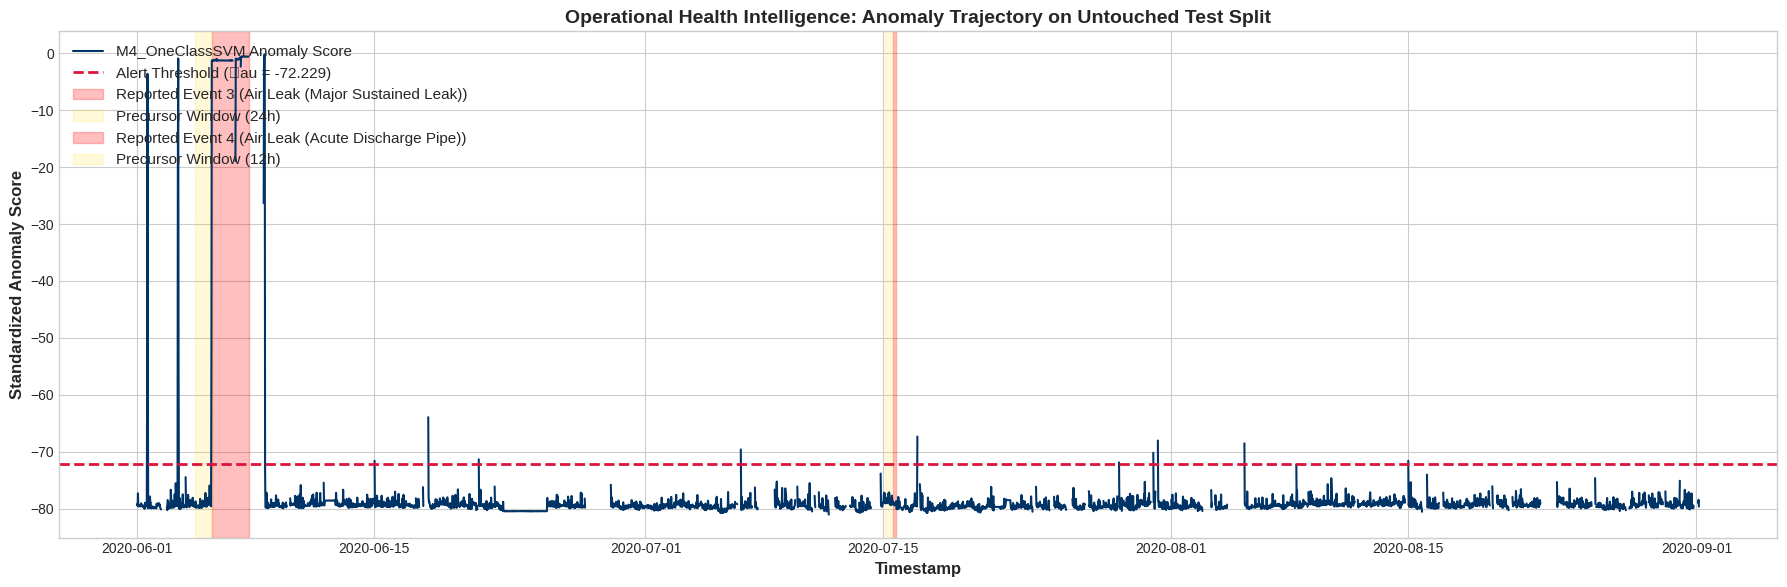

Top contextual deviations at test row 472, timestamp=2020-06-01 01:50:00:


,feature,absolute_scaled_deviation_from_training_median
3,DV_pressure,554.000000
20,DV_pressure_roll_std,9.649332
23,d_TP2_dt,8.000027
7,COMP,1.000000
8,DV_eletric,1.000000
18,is_pumping,1.000000
10,MPG,1.000000
22,d_Reservoirs_dt,0.978944
19,TP2_roll_std,0.912524
0,TP2,0.873756


Caution: these values show baseline-relative deviations; they are not SHAP values, model attributions, or proof of the physical cause.


In [24]:
# Visualization: Anomaly Trajectory Over Test Timeline
fig, ax = plt.subplots(figsize=(18, 6))

test_time = df_test[timestamp_col]
# Resample to 30-minute intervals for clear visualization
df_plot_test = pd.DataFrame({'time': test_time, 'score': best_test_scores}).set_index('time').resample('30min').mean().reset_index()

ax.plot(df_plot_test['time'], df_plot_test['score'], color='#003366', linewidth=1.5, label=f'{best_model_name} Anomaly Score')
ax.axhline(best_meta['Threshold'], color='crimson', linestyle='--', linewidth=2.0, label=f"Alert Threshold (\tau = {best_meta['Threshold']:.3f})")

# Shade Event 3 and Event 4
for _, evt in test_events.iterrows():
    ax.axvspan(evt['start_time'], evt['end_time'], color='red', alpha=0.25, label=f"Reported Event {evt['event_id']} ({evt['failure_type']})")
    # Shade the event-specific precursor duration defined in the event registry
    precursor_hours = float(evt.get('precursor_window_hours', 12))
    w_start = evt['start_time'] - pd.Timedelta(hours=precursor_hours)
    ax.axvspan(w_start, evt['start_time'], color='gold', alpha=0.15, label=f"Precursor Window ({precursor_hours:g}h)")

# Prevent duplicate labels in legend
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='upper left')

ax.set_title(f"Operational Health Intelligence: Anomaly Trajectory on Untouched Test Split", fontweight='bold', fontsize=14)
ax.set_ylabel("Standardized Anomaly Score", fontweight='bold')
ax.set_xlabel("Timestamp", fontweight='bold')
plt.tight_layout()
plt.show()

# Model-agnostic context for the highest-scoring row in the holdout set.
# This is a scaled deviation profile, not a model-specific attribution or causal explanation.
if len(best_test_scores) > 0:
    peak_idx = int(np.nanargmax(best_test_scores))
    deviation_profile = pd.DataFrame({
        'feature': feature_cols,
        'absolute_scaled_deviation_from_training_median': np.abs(X_test[peak_idx])
    }).sort_values('absolute_scaled_deviation_from_training_median', ascending=False).head(10)
    print(f"Top contextual deviations at test row {peak_idx}, timestamp={df_test.iloc[peak_idx][timestamp_col]}:")
    display(deviation_profile)
    print("Caution: these values show baseline-relative deviations; they are not SHAP values, model attributions, or proof of the physical cause.")


---
### Section L: Production-Grade Inference Pipeline

We encapsulate the complete data hygiene, validation, causal feature transformation, and model scoring pipeline into modular, reusable Python functions ready for deployment on incoming CSV telemetry.


In [25]:
class MetroPTPredictiveMaintenanceEngine:
    """CSV inference engine using the exact benchmark winner and training feature pipeline.

    Upload a chronologically ordered CSV that contains the same raw columns used for
    training. For rolling features, include historical context before the period to score.
    """
    def __init__(self, scaler, model_name, model_obj, feature_names, threshold,
                 raw_feature_names, timestamp_col='timestamp'):
        self.scaler = scaler
        self.model_name = model_name
        self.model = model_obj
        self.feature_names = list(feature_names)
        self.raw_feature_names = list(raw_feature_names)
        self.threshold = float(threshold)
        self.timestamp_col = timestamp_col

    def validate_schema(self, df):
        if not isinstance(df, pd.DataFrame) or df.empty:
            raise ValueError("Input telemetry must be a non-empty pandas DataFrame.")
        if self.timestamp_col not in df.columns:
            raise ValueError(
                f"Input CSV must contain timestamp column '{self.timestamp_col}' so rows can be ordered for rolling features."
            )
        missing = [c for c in self.raw_feature_names if c not in df.columns]
        if missing:
            raise ValueError(
                "Input CSV does not match the training schema. Missing raw feature columns: "
                + str(missing)
            )
        return True

    def transform_and_score(self, df_input):
        self.validate_schema(df_input)
        df_proc = df_input.copy()
        df_proc[self.timestamp_col] = pd.to_datetime(df_proc[self.timestamp_col], errors='coerce')
        if df_proc[self.timestamp_col].isna().any():
            bad_count = int(df_proc[self.timestamp_col].isna().sum())
            raise ValueError(f"Found {bad_count} invalid timestamps in input CSV.")
        df_proc = df_proc.sort_values(self.timestamp_col).reset_index(drop=True)

        # Shared function means rolling-window parameters and feature formulas cannot drift.
        df_proc = engineer_physics_features(df_proc, self.timestamp_col)
        missing_features = [c for c in self.feature_names if c not in df_proc.columns]
        if missing_features:
            raise ValueError(f"Feature engineering did not produce expected columns: {missing_features}")

        X_frame = df_proc[self.feature_names].replace([np.inf, -np.inf], np.nan)
        if X_frame.isna().any().any():
            bad_cols = X_frame.columns[X_frame.isna().any()].tolist()
            raise ValueError(
                f"Input feature matrix contains missing or infinite values in {bad_cols}. "
                "Clean these values using the same policy as the training data before inference."
            )
        X_scaled = self.scaler.transform(X_frame.to_numpy(dtype=np.float32))
        scores = score_anomaly_model(self.model_name, self.model, X_scaled)
        if len(scores) != len(df_proc):
            raise RuntimeError("Scoring returned a different number of values than input rows.")

        df_proc['anomaly_score'] = scores
        df_proc['is_anomaly'] = (scores >= self.threshold).astype('uint8')
        df_proc['model_name'] = self.model_name
        return df_proc


# Construct raw schema from the features that were present before physics-feature engineering.
raw_feature_names = [c for c in feature_cols if c not in ENGINEERED_FEATURE_NAMES]
prod_model_obj = model_objects[best_model_name]
engine = MetroPTPredictiveMaintenanceEngine(
    scaler=scaler,
    model_name=best_model_name,
    model_obj=prod_model_obj,
    feature_names=feature_cols,
    threshold=best_meta['Threshold'],
    raw_feature_names=raw_feature_names,
    timestamp_col=timestamp_col
)

# Test inference on a held-out segment. Includes enough earlier rows for rolling context
# and scores only the final 500 rows to avoid artificial start-of-file rolling effects.
if len(df_test) < 501:
    demo_input = df_test.copy()
else:
    demo_input = df_test.iloc[0:1500].copy()
scored_demo = engine.transform_and_score(demo_input)
scored_stream = scored_demo.tail(500).copy()
print("Inference pipeline test completed.")
print(f"Selected model: {best_model_name}")
print(f"Scored records: {len(scored_stream):,} | Alerts: {int(scored_stream['is_anomaly'].sum()):,}")
print(f"Threshold applied: {engine.threshold:.6f}")


Inference pipeline test completed.
Selected model: M4_OneClassSVM
Scored records: 500 | Alerts: 2
Threshold applied: -72.229472


---
### Section M: LLM Integration Preparation (Structured JSON Payload for Gemini Flash)

To prepare for downstream integration with conversational AI (such as Gemini Flash) without requiring an API key during training, we construct a structured, schema-compliant JSON payload that encapsulates:
1. Verified sensor facts (pressures, current, oil temperature).
2. Model anomaly score and alert status.
3. Physical explanations and recommended maintenance verifications.
4. An actionable zero-hallucination prompt template.


In [26]:
def generate_gemini_flash_payload(df_scored, incident_timestamp=None):
    """Create a JSON-safe summary for a downstream Gemini Flash assistant (no API call here)."""
    if df_scored is None or df_scored.empty:
        raise ValueError("Cannot create a Gemini payload from an empty scored dataframe.")

    if incident_timestamp is not None:
        target = pd.to_datetime(incident_timestamp, errors='coerce')
        times = pd.to_datetime(df_scored[timestamp_col], errors='coerce')
        matches = df_scored.loc[times == target]
        if matches.empty:
            raise ValueError(f"No scored row was found at incident timestamp {incident_timestamp!r}.")
        row = matches.iloc[0]
    else:
        row = df_scored.sort_values(by='anomaly_score', ascending=False).iloc[0]

    def safe_float(value):
        try:
            numeric = float(value)
            return numeric if np.isfinite(numeric) else None
        except (TypeError, ValueError):
            return None

    payload = {
        "machine_type": "Metro-Train Air Compressor (MetroPT-3 dataset domain)",
        "timestamp": str(row[timestamp_col]),
        "model_metadata": {
            "model_name": str(row.get('model_name', best_model_name)),
            "model_type": str(best_meta['Category']),
            "threshold": safe_float(best_meta['Threshold']),
            "score": safe_float(row['anomaly_score']),
            "anomaly_detected": bool(row['is_anomaly'] == 1),
            "evaluation_caveat": "Anomaly score is not a confirmed failure diagnosis."
        },
        "sensor_telemetry": {
            "TP2_compressor_pressure": safe_float(row.get('TP2')),
            "TP3_panel_pressure": safe_float(row.get('TP3')),
            "H1_cyclonic_separator_pressure": safe_float(row.get('H1')),
            "DV_pressure": safe_float(row.get('DV_pressure')),
            "Reservoir_pressure": safe_float(row.get('Reservoirs')),
            "Motor_current": safe_float(row.get('Motor_current')),
            "Oil_temperature": safe_float(row.get('Oil_temperature')),
            "Differential_TP2_TP3": safe_float(row.get('delta_TP2_TP3')),
            "Reservoir_decay_rate_per_sample": safe_float(row.get('d_Reservoirs_dt'))
        },
        "operating_context": {
            "compressor_pumping": bool(row['Motor_current'] > 1.0) if pd.notna(row.get('Motor_current')) else None,
            "abnormal_decay_while_idle": bool(row['leak_signature_score'] > 0.05) if pd.notna(row.get('leak_signature_score')) else None
        },
        "recommended_checks": [
            "Review the pressure and operating-state trends around this timestamp.",
            "Inspect relevant valves, couplings, and seals if the alert persists.",
            "Confirm any suspected fault with maintenance logs and a qualified technician."
        ],
        "uncertainty_note": (
            "This system flags statistical anomalies in MetroPT-3-like compressor telemetry. "
            "It is not a confirmed diagnosis, and documented event labels are sparse."
        )
    }
    return payload


sample_gemini_payload = generate_gemini_flash_payload(scored_stream)
print("Gemini Flash payload (structured data only; no API call made):")
print(json.dumps(sample_gemini_payload, indent=2, allow_nan=False))


Gemini Flash payload (structured data only; no API call made):
{
  "machine_type": "Metro-Train Air Compressor (MetroPT-3 dataset domain)",
  "timestamp": "2020-06-01 03:33:34",
  "model_metadata": {
    "model_name": "M4_OneClassSVM",
    "model_type": "Kernel Boundary",
    "threshold": -72.22947207420354,
    "score": -1.355660569673816,
    "anomaly_detected": true,
    "evaluation_caveat": "Anomaly score is not a confirmed failure diagnosis."
  },
  "sensor_telemetry": {
    "TP2_compressor_pressure": 1.899999976158142,
    "TP3_panel_pressure": 10.152000427246094,
    "H1_cyclonic_separator_pressure": 10.154000282287598,
    "DV_pressure": 1.600000023841858,
    "Reservoir_pressure": 10.152000427246094,
    "Motor_current": 4.074999809265137,
    "Oil_temperature": 65.55000305175781,
    "Differential_TP2_TP3": -8.25200080871582,
    "Reservoir_decay_rate_per_sample": 0.13000011444091797
  },
  "operating_context": {
    "compressor_pumping": true,
    "abnormal_decay_while_idle"

In [27]:
# Sample Prompt for Downstream Gemini Flash Conversational Assistant
gemini_prompt_template = f"""
SYSTEM INSTRUCTION:
You are an expert Rolling Stock Mechanical Engineer and Predictive Maintenance Specialist.
Analyze the following JSON machine health telemetry report generated by an onboard anomaly detector for a metro-train air compressor.

RULES:
1. Rely ONLY on the observed sensor telemetry and physics-based facts provided in the JSON payload.
2. DO NOT invent, hallucinate, or extrapolate failure causes not directly evidenced by the pressure and current readings.
3. Clearly state whether the compressor is currently actively pumping or unpowered/idling.
4. Distinguish between normal operational transients and genuine mechanical anomalies.
5. Provide actionable, concise maintenance recommendations suitable for rolling-stock depot technicians.

JSON TELEMETRY PAYLOAD:
{json.dumps(sample_gemini_payload, indent=2)}

ASSISTANT RESPONSE FORMAT:
- Machine Health Status: [Normal / Warning / Critical Anomaly]
- Key Sensor Observations: [Bullet points referencing exact bar, A, and °C readings]
- Physical Mechanism Analysis: [Thermodynamic/pneumatic explanation of the observed state]
- Recommended Technician Actions: [Step-by-step physical inspection protocol]
- Uncertainty & Limitations: [Statement on false alarm risks and non-exhaustive sensor coverage]
"""

print("Prompt Template Configured for Gemini Flash Integration:")
print(gemini_prompt_template[:600] + "...\n[TRUNCATED FOR DISPLAY]")


Prompt Template Configured for Gemini Flash Integration:

SYSTEM INSTRUCTION:
You are an expert Rolling Stock Mechanical Engineer and Predictive Maintenance Specialist.
Analyze the following JSON machine health telemetry report generated by an onboard anomaly detector for a metro-train air compressor.

RULES:
1. Rely ONLY on the observed sensor telemetry and physics-based facts provided in the JSON payload.
2. DO NOT invent, hallucinate, or extrapolate failure causes not directly evidenced by the pressure and current readings.
3. Clearly state whether the compressor is currently actively pumping or unpowered/idling.
4. Distinguish between normal ope...
[TRUNCATED FOR DISPLAY]


### Section N: Score a User-Uploaded Historical CSV

After training and creating `engine`, use `score_uploaded_csv(...)` to analyze a CSV file. The CSV must contain the timestamp column and all raw features listed in `raw_feature_names`, using the same column names and units as MetroPT-3. The function scores the rows, optionally saves the scored CSV, and creates a JSON payload for a future Gemini Flash call. It does not call Gemini or require an API key.

In [28]:
def score_uploaded_csv(csv_path, scored_output_path=None, payload_output_path=None):
    """Score a user-provided historical telemetry CSV with the selected trained model.

    Parameters
    ----------
    csv_path : str or pathlib.Path
        Path to the uploaded MetroPT-3-compatible CSV.
    scored_output_path : optional str or pathlib.Path
        Where to save row-level anomaly scores and flags. If None, do not write a CSV.
    payload_output_path : optional str or pathlib.Path
        Where to save a JSON summary for downstream Gemini Flash integration.
        If None, do not write a JSON file.

    Returns
    -------
    scored_dataframe, gemini_payload
    """
    uploaded_df = pd.read_csv(csv_path)
    scored_df = engine.transform_and_score(uploaded_df)
    payload = generate_gemini_flash_payload(scored_df)

    if scored_output_path is not None:
        scored_df.to_csv(scored_output_path, index=False)
        print(f"Saved row-level scores to: {scored_output_path}")
    if payload_output_path is not None:
        with open(payload_output_path, "w", encoding="utf-8") as f:
            json.dump(payload, f, indent=2, allow_nan=False)
        print(f"Saved Gemini-ready JSON payload to: {payload_output_path}")

    print(f"Scored {len(scored_df):,} rows using {best_model_name}.")
    print(f"Anomaly flags: {int(scored_df['is_anomaly'].sum()):,}")
    return scored_df, payload


# Example (edit paths to match the file you upload in Jupyter):
# scored_df, gemini_payload = score_uploaded_csv(
#     "uploaded_compressor_history.csv",
#     scored_output_path="scored_compressor_history.csv",
#     payload_output_path="gemini_flash_payload.json"
# )
print("CSV inference helper is ready. Supply your uploaded file path to score_uploaded_csv(...).")

CSV inference helper is ready. Supply your uploaded file path to score_uploaded_csv(...).


---
### Section O: Production Artifact Serialization

We save all operational components (trained model, fitted scaler, feature schemas, decision thresholds, and metadata) using `joblib` and `json` for deployment in automated microservices or streaming edge runtimes.


In [29]:
# Artifact Serialization
artifacts_dir = "metropt_model_artifacts"
os.makedirs(artifacts_dir, exist_ok=True)

scaler_path = os.path.join(artifacts_dir, "robust_scaler.joblib")
model_path = os.path.join(artifacts_dir, "selected_anomaly_model.joblib")
metadata_path = os.path.join(artifacts_dir, "pipeline_metadata.json")

joblib.dump(scaler, scaler_path)
# This is the exact object used by the inference engine, not a hard-coded fallback model.
joblib.dump(prod_model_obj, model_path)

pipeline_metadata = {
    "project_name": "AI-Powered Predictive Maintenance - MetroPT-3 Air Compressor",
    "saved_timestamp": datetime.now().isoformat(),
    "best_model_name": best_model_name,
    "model_category": best_meta['Category'],
    "score_direction": "higher means more anomalous",
    "selection_criterion": "highest validation PR-AUC against sparse event-derived weak labels",
    "alert_threshold": float(best_meta['Threshold']),
    "feature_columns": list(feature_cols),
    "raw_feature_columns": list(raw_feature_names),
    "engineered_feature_columns": list(ENGINEERED_FEATURE_NAMES),
    "required_timestamp_column": timestamp_col,
    "roll_window_samples": int(ROLL_WINDOW),
    "rolling_min_periods": 5,
    "sampling_interval_seconds": 10,
    "validation_pr_auc_weak_labels": float(best_meta['PR_AUC']),
    "validation_f1_weak_labels": float(best_meta['F1_Score']),
    "validation_fpr_weak_labels": float(best_meta['FPR']),
    "important_caveat": "Rows outside documented event windows are not confirmed healthy labels. Metrics are exploratory, not validated real-world failure-prediction performance."
}
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(pipeline_metadata, f, indent=2, allow_nan=False)

print(f"[SUCCESS] Saved deployment artifacts to: {artifacts_dir}/")
for filename in [scaler_path, model_path, metadata_path]:
    print(f"  - {os.path.basename(filename)} ({os.path.getsize(filename) / 1024:.2f} KB)")


[SUCCESS] Saved deployment artifacts to: metropt_model_artifacts/
  - robust_scaler.joblib (0.81 KB)
  - selected_anomaly_model.joblib (131.59 KB)
  - pipeline_metadata.json (1.87 KB)


In [30]:
# Reload Verification: scaler, selected model, metadata, and scoring consistency
reloaded_scaler = joblib.load(os.path.join(artifacts_dir, "robust_scaler.joblib"))
reloaded_model = joblib.load(os.path.join(artifacts_dir, "selected_anomaly_model.joblib"))
with open(os.path.join(artifacts_dir, "pipeline_metadata.json"), "r", encoding="utf-8") as f:
    reloaded_meta = json.load(f)

n_check = min(10, len(X_test))
if n_check == 0:
    raise RuntimeError("Holdout set is empty; cannot perform reload verification.")
raw_check = df_test[feature_cols].iloc[:n_check].to_numpy(dtype=np.float32)
scaled_check = reloaded_scaler.transform(raw_check)
original_scaled_check = X_test[:n_check]
if not np.allclose(scaled_check, original_scaled_check, rtol=1e-5, atol=1e-6):
    raise AssertionError("Reloaded scaler does not reproduce the saved test feature scaling.")

reloaded_scores = score_anomaly_model(reloaded_meta['best_model_name'], reloaded_model, scaled_check)
original_scores = score_anomaly_model(best_model_name, prod_model_obj, X_test[:n_check])
if not np.allclose(reloaded_scores, original_scores, rtol=1e-5, atol=1e-6):
    raise AssertionError("Reloaded model scores do not match scores from the selected model.")

print("[VERIFICATION PASSED] Reloaded scaler and exact selected model reproduce the original scores.")
print(f"Model: {reloaded_meta['best_model_name']} | Rows checked: {n_check}")
print(f"First scores: {np.round(reloaded_scores[:5], 6).tolist()}")


[VERIFICATION PASSED] Reloaded scaler and exact selected model reproduce the original scores.
Model: M4_OneClassSVM | Rows checked: 10
First scores: [-45.320442, -79.16781, -79.46254, -78.959596, -78.861197]


---
### Section P: Scientific Conclusions, Operational Insights, and Reproducibility Checklist

#### 1. How to Interpret the Results
- **Task supported:** This notebook trains unsupervised anomaly detectors. It does not establish supervised failure classification or remaining-useful-life prediction because MetroPT-3 provides only sparse reported maintenance intervals, not complete row-level failure labels.
- **Model selection:** The leaderboard chooses the highest validation PR-AUC against event-derived weak labels. The selected model and its metrics depend on the actual execution; do not claim a model universally outperforms the others.
- **Early warnings:** An event is counted as detected only when the configured persistence rule is met during its event interval or documented precursor window. Any calculated lead time is exploratory and should be reported alongside the raw event table and false-alarm-cluster estimate.
- **Interpretation of labels:** Rows outside the four documented intervals are not confirmed healthy. Pointwise PR-AUC, F1, precision, recall, and FPR are exploratory metrics against weak labels, not verified real-world failure-prediction performance.
- **Physical explanations:** A high anomaly score signals unusual telemetry relative to the learned baseline. It does not by itself identify a failed component or prove an air leak; technicians must verify the sensor evidence.

#### 2. What Would Be Needed for Supervised RUL Estimation?
1. Multiple continuous run-to-failure cycles without intermediate patch repairs.
2. Verified component degradation logs detailing exact mechanical clearances and valve fatigue states.
3. Fleet-wide data across multiple trainsets and operating conditions.

#### 3. Reproducibility Checklist
Complete these checks after running the notebook from the first cell to the last:
- [ ] Dataset path resolves and the schema / sampling-frequency audit completes.
- [ ] All seven model benchmarks finish, and the validation leaderboard is produced.
- [ ] Event-level detection and false-alarm-cluster summaries are reviewed with weak-label caveats.
- [ ] The selected-model inference test returns the expected number of rows without a forced model fallback.
- [ ] A user-uploaded CSV with the required schema can be scored and exported.
- [ ] Scaler/model artifacts save and reload verification passes.
- [ ] The Gemini-ready JSON payload is valid JSON; no Gemini API call is made during notebook training.


In [31]:
import os

for root, dirs, files in os.walk("/kaggle/working"):
    dirs[:] = [d for d in dirs if not d.startswith(".")]
    for filename in files:
        if filename.endswith((".joblib", ".pkl", ".pickle", ".pt", ".pth")):
            print(os.path.join(root, filename))

/kaggle/working/metropt_model_artifacts/selected_anomaly_model.joblib
/kaggle/working/metropt_model_artifacts/robust_scaler.joblib


In [32]:
import os
import joblib

artifact_dir = "/kaggle/working/metropt_model_artifacts"

model_path = os.path.join(
    artifact_dir, "selected_anomaly_model.joblib"
)
scaler_path = os.path.join(
    artifact_dir, "robust_scaler.joblib"
)

model = joblib.load(model_path)
scaler = joblib.load(scaler_path)

print("Model loaded:", type(model).__name__)
print("Scaler loaded:", type(scaler).__name__)

if hasattr(model, "get_params"):
    print("\nModel parameters:")
    print(model.get_params())

if hasattr(scaler, "n_features_in_"):
    print("\nScaler input feature count:", scaler.n_features_in_)

if hasattr(scaler, "feature_names_in_"):
    print("Scaler feature names:")
    print(list(scaler.feature_names_in_))

Model loaded: OneClassSVM
Scaler loaded: RobustScaler

Model parameters:
{'cache_size': 200, 'coef0': 0.0, 'degree': 3, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'nu': 0.03, 'shrinking': True, 'tol': 0.001, 'verbose': False}

Scaler input feature count: 25


In [33]:
import os
import json

artifact_dir = "/kaggle/working/metropt_model_artifacts"

print("Saved artifacts:")
print(os.listdir(artifact_dir))

metadata_path = os.path.join(
    artifact_dir,
    "pipeline_metadata.json"
)

if os.path.exists(metadata_path):
    with open(metadata_path, "r", encoding="utf-8") as f:
        metadata = json.load(f)

    print("\nPipeline metadata:")
    print(json.dumps(metadata, indent=2))
else:
    print("\npipeline_metadata.json was not found.")

Saved artifacts:
['pipeline_metadata.json', 'selected_anomaly_model.joblib', 'robust_scaler.joblib']

Pipeline metadata:
{
  "project_name": "AI-Powered Predictive Maintenance - MetroPT-3 Air Compressor",
  "saved_timestamp": "2026-10-24T23:10:20.136066",
  "best_model_name": "M4_OneClassSVM",
  "model_category": "Kernel Boundary",
  "score_direction": "higher means more anomalous",
  "selection_criterion": "highest validation PR-AUC against sparse event-derived weak labels",
  "alert_threshold": -72.22947207420354,
  "feature_columns": [
    "TP2",
    "TP3",
    "H1",
    "DV_pressure",
    "Reservoirs",
    "Oil_temperature",
    "Motor_current",
    "COMP",
    "DV_eletric",
    "Towers",
    "MPG",
    "LPS",
    "Pressure_switch",
    "Oil_level",
    "Caudal_impulses",
    "delta_TP2_TP3",
    "delta_TP3_Reservoirs",
    "delta_H1_TP2",
    "is_pumping",
    "TP2_roll_std",
    "DV_pressure_roll_std",
    "Oil_temp_roll_mean",
    "d_Reservoirs_dt",
    "d_TP2_dt",
    "leak_sig

In [34]:

import os
import json
import joblib
import numpy as np

artifact_dir = "/kaggle/working/metropt_model_artifacts"

# Load saved artifacts
saved_model = joblib.load(
    os.path.join(artifact_dir, "selected_anomaly_model.joblib")
)

saved_scaler = joblib.load(
    os.path.join(artifact_dir, "robust_scaler.joblib")
)

with open(
    os.path.join(artifact_dir, "pipeline_metadata.json"),
    "r",
    encoding="utf-8"
) as f:
    saved_metadata = json.load(f)

# Verify the saved configuration
feature_columns = saved_metadata["feature_columns"]

print("Model:", saved_metadata["best_model_name"])
print("Model type:", type(saved_model).__name__)
print("Scaler type:", type(saved_scaler).__name__)
print("Expected feature count:", len(feature_columns))
print("Scaler feature count:", saved_scaler.n_features_in_)
print("Threshold:", saved_metadata["alert_threshold"])

assert len(feature_columns) == saved_scaler.n_features_in_, (
    "Feature count mismatch between metadata and scaler."
)

print("\nSaved artifacts and feature counts verified.")


Model: M4_OneClassSVM
Model type: OneClassSVM
Scaler type: RobustScaler
Expected feature count: 25
Scaler feature count: 25
Threshold: -72.22947207420354

Saved artifacts and feature counts verified.


In [35]:

required_objects = [
    "df_test",
    "feature_cols",
    "timestamp_col",
    "ENGINEERED_FEATURE_NAMES",
    "engineer_physics_features",
    "score_anomaly_model",
    "MetroPTPredictiveMaintenanceEngine",
    "best_model_name",
    "best_meta",
    "model_objects",
    "scored_stream",
    "generate_gemini_flash_payload",
]

for name in required_objects:
    print(f"{name}: {'READY' if name in globals() else 'MISSING'}")


df_test: READY
feature_cols: READY
timestamp_col: READY
ENGINEERED_FEATURE_NAMES: READY
engineer_physics_features: READY
score_anomaly_model: READY
MetroPTPredictiveMaintenanceEngine: READY
best_model_name: READY
best_meta: READY
model_objects: READY
scored_stream: READY
generate_gemini_flash_payload: READY


In [36]:

import json

# Generate a compact report from the existing anomaly scores
gemini_payload = generate_gemini_flash_payload(scored_stream)

# Verify that the payload is valid JSON
payload_json = json.dumps(
    gemini_payload,
    indent=2,
    allow_nan=False
)

print("Payload generated successfully.")
print(payload_json)


Payload generated successfully.
{
  "machine_type": "Metro-Train Air Compressor (MetroPT-3 dataset domain)",
  "timestamp": "2020-06-01 03:33:34",
  "model_metadata": {
    "model_name": "M4_OneClassSVM",
    "model_type": "Kernel Boundary",
    "threshold": -72.22947207420354,
    "score": -1.355660569673816,
    "anomaly_detected": true,
    "evaluation_caveat": "Anomaly score is not a confirmed failure diagnosis."
  },
  "sensor_telemetry": {
    "TP2_compressor_pressure": 1.899999976158142,
    "TP3_panel_pressure": 10.152000427246094,
    "H1_cyclonic_separator_pressure": 10.154000282287598,
    "DV_pressure": 1.600000023841858,
    "Reservoir_pressure": 10.152000427246094,
    "Motor_current": 4.074999809265137,
    "Oil_temperature": 65.55000305175781,
    "Differential_TP2_TP3": -8.25200080871582,
    "Reservoir_decay_rate_per_sample": 0.13000011444091797
  },
  "operating_context": {
    "compressor_pumping": true,
    "abnormal_decay_while_idle": false
  },
  "recommended_che

In [39]:

from kaggle_secrets import UserSecretsClient
from google import genai

# Retrieve your API key securely from Kaggle Secrets
user_secrets = UserSecretsClient()
api_key = user_secrets.get_secret("GEMINI_API_KEY")

# Initialize the Gemini client
client = genai.Client(api_key=api_key)

print("Gemini client initialized successfully!")


Gemini client initialized successfully!


In [41]:

from google.genai import types

system_instruction = """
You are a careful predictive-maintenance assistant analyzing
metro-train air-compressor telemetry.

Use only information supported by the supplied JSON payload.
Do not invent sensor readings or claim a component has failed
without evidence.

An anomaly score is not a confirmed diagnosis.
Clearly distinguish observed facts from possible explanations.
Recommend safe verification by a qualified technician.
Do not claim to predict remaining useful life.
"""

prompt = f"""
Analyze this machine-health payload:

{payload_json}

Write a concise maintenance report containing:

1. Machine health status: Normal, Warning, or Critical Anomaly.
2. The model alert and its supporting sensor readings.
3. Plausible explanations, clearly labeled as hypotheses.
4. Prioritized checks for a maintenance technician.
5. Uncertainty and limitations.

Base the status on the model alert and available evidence.
Do not invent severity thresholds or diagnose a confirmed failure.
"""


response = client.models.generate_content(
    model="gemini-3.8-flash",
    contents=prompt,
    config=types.GenerateContentConfig(
        system_instruction=system_instruction,
    ),
)

print(response.text)



### Predictive Maintenance Report

**Machine Type:** Metro-Train Air Compressor (MetroPT-3 domain)  
**Timestamp:** 2020-06-01 03:33:34  

---

### 1. Machine Health Status
* **Status:** **Warning** (Statistical Anomaly Detected)  
*(Note: Based on the anomaly flag from the model; this does not denote a confirmed mechanical failure.)*

---

### 2. Model Alert and Supporting Sensor Readings
* **Model Alert:** 
  * **Model:** M4_OneClassSVM (Kernel Boundary)
  * **Anomaly Detected:** `true`
  * **Score:** `-1.3557` (Threshold: `-72.2295`)
* **Operating Context:**
  * Compressor pumping: `true`
  * Abnormal decay while idle: `false`
* **Sensor Telemetry:**
  * **TP2 Compressor Pressure:** 1.90 bar
  * **TP3 Panel Pressure:** 10.15 bar
  * **H1 Cyclonic Separator Pressure:** 10.15 bar
  * **Reservoir Pressure:** 10.15 bar
  * **DV Pressure:** 1.60 bar
  * **Pressure Differential (TP2 - TP3):** -8.25 bar
  * **Reservoir Decay Rate per Sample:** 0.13
  * **Motor Current:** 4.07 A
  * **Oil T

In [88]:
# Project implementation status check
print("=== Predictive Maintenance Project ===")

checks = {
    "Original model": "M4_OneClassSVM" in globals().get("model_results", {}),
    "Training features": "X_train" in globals(),
    "Validation features": "X_val" in globals(),
    "Test features": "X_test" in globals(),
    "Feature names": "feature_cols" in globals(),
    "Training scaler": "scaler" in globals(),
    "Original anomaly threshold": "m4_thresh" in globals(),
    "Prediction engine": "MetroPTPredictiveMaintenanceEngine" in globals(),
    "Gemini API function": any(
        name in globals()
        for name in ["generate_gemini_report", "generate_ai_explanation"]
    ),
}

for component, available in checks.items():
    print(f"{'READY' if available else 'NOT FOUND'}: {component}")

=== Predictive Maintenance Project ===
READY: Original model
READY: Training features
READY: Validation features
READY: Test features
READY: Feature names
READY: Training scaler
READY: Original anomaly threshold
READY: Prediction engine
NOT FOUND: Gemini API function


In [91]:
import inspect

print("=== Searching for Gemini API calls ===")

patterns = [
    "generate_content",
    "generativelanguage.googleapis.com",
    "google.generativeai",
    "google.genai",
    "genai.Client",
    "GenerativeModel",
]

found = False

for name, obj in list(globals().items()):
    if inspect.isfunction(obj) or inspect.isclass(obj):
        try:
            source = inspect.getsource(obj)
            matches = [p for p in patterns if p.lower() in source.lower()]

            if matches:
                print(f"\nName: {name}")
                print(f"Type: {'class' if inspect.isclass(obj) else 'function'}")
                print(f"Matched patterns: {', '.join(matches)}")
                found = True
        except (OSError, TypeError):
            pass

if not found:
    print("No matching API calls found in currently loaded functions/classes.")
    print("The API call may be in an unexecuted notebook cell.")

=== Searching for Gemini API calls ===
No matching API calls found in currently loaded functions/classes.
The API call may be in an unexecuted notebook cell.


In [92]:
# Check which Gemini SDK is available
try:
    from google import genai
    print("New Google GenAI SDK is available.")
except ImportError:
    print("New Google GenAI SDK is not installed.")

try:
    import google.generativeai as genai_old
    print("Legacy Google Generative AI SDK is available.")
except ImportError:
    print("Legacy Google Generative AI SDK is not installed.")

New Google GenAI SDK is available.
Legacy Google Generative AI SDK is available.


In [94]:
import json

def generate_gemini_explanation(payload, prompt_template):
    """
    Generate a maintenance explanation using the supplied telemetry payload.
    """
    if not isinstance(payload, dict):
        raise TypeError("payload must be a dictionary.")

    # Replace the embedded sample JSON with the actual supplied payload.
    payload_json = json.dumps(payload, indent=2, allow_nan=False)

    marker = "JSON TELEMETRY PAYLOAD:"
    format_marker = "\nASSISTANT RESPONSE FORMAT:"

    if marker not in prompt_template or format_marker not in prompt_template:
        raise ValueError("The prompt template does not contain the expected sections.")

    instructions = prompt_template.split(marker, 1)[0]
    response_format = format_marker + prompt_template.split(format_marker, 1)[1]

    actual_prompt = (
        instructions
        + marker + "\n"
        + payload_json
        + response_format
    )

    response = gemini_client.models.generate_content(
        model="gemini-3.8-flash",
        contents=actual_prompt
    )

    if not response.text:
        raise RuntimeError("Gemini returned an empty response.")

    return response.text

print("Gemini function updated: it now uses the supplied payload.")

Gemini function updated: it now uses the supplied payload.


In [95]:
# Generate a report using the existing sample telemetry
gemini_report = generate_gemini_explanation(
    payload=sample_gemini_payload,
    prompt_template=gemini_prompt_template
)

print("=== AI-GENERATED MAINTENANCE REPORT ===\n")
print(gemini_report)

=== AI-GENERATED MAINTENANCE REPORT ===

- **Machine Health Status:** Warning

- **Key Sensor Observations:**
  - **Compressor Outlet Pressure (TP2):** 1.90 bar
  - **Downstream Panel Pressure (TP3):** 10.15 bar
  - **Cyclonic Separator Pressure (H1):** 10.15 bar
  - **Drain Valve Pressure (DV):** 1.60 bar
  - **Main Reservoir Pressure:** 10.15 bar
  - **Motor Current:** 4.07 A
  - **Oil Temperature:** 65.55 °C
  - **Pressure Differential (TP2 – TP3):** -8.25 bar
  - **Reservoir Pressure Decay Rate:** 0.13 bar/sample

- **Physical Mechanism Analysis:**
  - **Operational State:** The telemetry registers the system as actively pumping (`compressor_pumping: true`).
  - **Pneumatic Disparity:** The compressor outlet pressure (TP2 at 1.90 bar) is substantially lower than downstream panel and reservoir pressures (10.15 bar), yielding a differential of -8.25 bar. To overcome the non-return/check valve and deliver air into the main reservoir, TP2 must exceed downstream line pressure (>10.15 ba

In [96]:
# Select the most anomalous observation from the existing scored stream
actual_payload = generate_gemini_flash_payload(scored_stream)

print("Selected timestamp:", actual_payload["timestamp"])
print("Model:", actual_payload["model_metadata"]["model_name"])
print("Anomaly score:", actual_payload["model_metadata"]["score"])
print("Threshold:", actual_payload["model_metadata"]["threshold"])
print("Anomaly detected:", actual_payload["model_metadata"]["anomaly_detected"])

Selected timestamp: 2020-06-01 03:33:34
Model: M4_OneClassSVM
Anomaly score: -1.355660569673816
Threshold: -72.22947207420354
Anomaly detected: True


In [97]:
actual_gemini_report = generate_gemini_explanation(
    payload=actual_payload,
    prompt_template=gemini_prompt_template
)

print("=== MAINTENANCE REPORT FOR ACTUAL SCORED OBSERVATION ===\n")
print(actual_gemini_report)

=== MAINTENANCE REPORT FOR ACTUAL SCORED OBSERVATION ===

- **Machine Health Status:** Warning

- **Key Sensor Observations:**
  - **Compressor Discharge Pressure (TP2):** 1.90 bar
  - **Panel Pressure (TP3):** 10.15 bar
  - **Cyclonic Separator Pressure (H1):** 10.15 bar
  - **Main Reservoir Pressure:** 10.15 bar
  - **Drain/Purge Valve Pressure (DV):** 1.60 bar
  - **Differential Pressure (TP2 - TP3):** -8.25 bar
  - **Motor Current:** 4.07 A
  - **Oil Temperature:** 65.55 °C
  - **Reservoir Pressure Decay Rate:** 0.13 bar/sample

- **Physical Mechanism Analysis:**
  - **Operating State:** The logical context flags the unit as `compressor_pumping: true`. However, physical telemetry indicates the compressor is **not actively delivering air into the main reservoir** (operating in an unloaded, startup, or depressurized state):
    - Downstream pressure (TP3, H1, and Main Reservoir) is charged to full system pressure (~10.15 bar).
    - Compressor discharge pressure (TP2) is only 1.90 ba

In [98]:
def explain_anomaly_at(incident_timestamp):
    """
    Generate a Gemini maintenance report for a specific scored observation.
    """
    payload = generate_gemini_flash_payload(
        scored_stream,
        incident_timestamp=incident_timestamp
    )

    report = generate_gemini_explanation(
        payload=payload,
        prompt_template=gemini_prompt_template
    )

    return {
        "timestamp": payload["timestamp"],
        "anomaly_detected": payload["model_metadata"]["anomaly_detected"],
        "anomaly_score": payload["model_metadata"]["score"],
        "threshold": payload["model_metadata"]["threshold"],
        "report": report
    }

print("Reusable anomaly explanation function created successfully.")

Reusable anomaly explanation function created successfully.


In [99]:
incident_report = explain_anomaly_at("2020-06-01 03:33:34")

print("Timestamp:", incident_report["timestamp"])
print("Anomaly detected:", incident_report["anomaly_detected"])
print("Anomaly score:", incident_report["anomaly_score"])
print("Threshold:", incident_report["threshold"])

print("\n" + "=" * 60)
print("GEMINI MAINTENANCE REPORT")
print("=" * 60)
print(incident_report["report"])

Timestamp: 2020-06-01 03:33:34
Anomaly detected: True
Anomaly score: -1.355660569673816
Threshold: -72.22947207420354

GEMINI MAINTENANCE REPORT
- **Machine Health Status:** Warning (Pneumatic Delivery Discrepancy / State Transition Anomaly)

- **Key Sensor Observations:**
  - **Compressor Discharge Pressure (TP2):** 1.90 bar
  - **Panel Pressure (TP3):** 10.15 bar
  - **Cyclonic Separator Pressure (H1):** 10.15 bar
  - **Main Reservoir Pressure:** 10.15 bar
  - **Drain/Discharge Valve Pressure (DV):** 1.60 bar
  - **Differential Pressure (TP2 – TP3):** -8.25 bar
  - **Motor Current:** 4.07 A
  - **Oil Temperature:** 65.55 °C (within normal operating band)
  - **Reservoir Decay Rate:** 0.13 bar/sample
  - **Detector Output:** Anomaly confirmed (`anomaly_detected: true`, score: -1.36 vs threshold: -72.23)

- **Physical Mechanism Analysis:**
  - **Operational State:** While the control flag denotes `compressor_pumping: true`, the unit is **not actively delivering air to the reservoir**. 

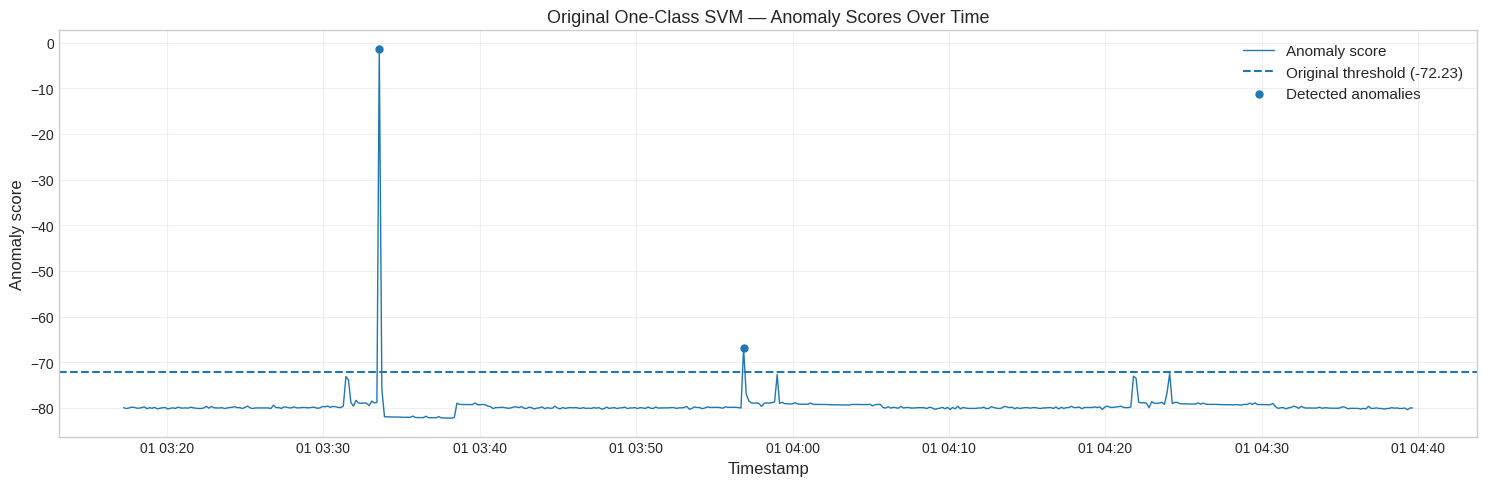

In [109]:
import matplotlib.pyplot as plt

# Using existing scored data
plot_df = scored_stream.copy()
plot_df[timestamp_col] = pd.to_datetime(plot_df[timestamp_col])

plt.figure(figsize=(15, 5))

plt.plot(
    plot_df[timestamp_col],
    plot_df["anomaly_score"],
    label="Anomaly score",
    linewidth=1
)

plt.axhline(
    y=m4_thresh,
    linestyle="--",
    label=f"Original threshold ({m4_thresh:.2f})"
)

anomalies = plot_df[plot_df["is_anomaly"] == 1]

plt.scatter(
    anomalies[timestamp_col],
    anomalies["anomaly_score"],
    label="Detected anomalies",
    s=25
)

plt.title("Original One-Class SVM — Anomaly Scores Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Anomaly score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()